# MODEL_POISSON — Prédire le score d'un match de Ligue des Champions

**Groupe :** Maxime, Loan, Moussa, Mouhamedou et Ousmane — partie modèle : Moussa

> **Nous prédisons le score d'un match de Ligue des Champions avant le coup d'envoi, pour estimer la probabilité de titre de chaque club en 2026-2027.**

## Objectif
Prédire **le score** d'un match de C1 avant le coup d'envoi, pas seulement son vainqueur. La simulation de la saison 2026-2027 a besoin de scores pour deux règles de l'UEFA :
- en **phase de ligue**, les égalités de points se départagent à la **différence de buts**, puis aux buts marqués ;
- en **phase finale**, les matchs aller-retour se jouent sur le **score cumulé**.

## Résumé
- **Le modèle de Poisson prédit le vainqueur aussi bien que le modèle actuel**, et il donne en plus des scores : log loss de **0,902** sur le test 2023-2025, contre 0,904 pour la logistique ordinale et 1,020 pour le Dummy. L'écart avec la logistique n'est pas significatif.
- **Ses scores sont crédibles** : il trouve le score exact dans **9,8 %** des matchs (6,6 % pour la règle « toujours 1-1 »), et ses probabilités sont bien calibrées.
- **Il bat toutes les baselines** : sur le test, 58,6 % d'accuracy (Dummy 50,0 %), 45,5 % de balanced accuracy (Dummy 33,3 %), et une erreur moyenne de **1,03 but** par équipe contre 1,14 pour le `DummyRegressor`. Sur la question de l'atelier, « victoire à domicile oui/non », il a raison dans **68,1 %** des matchs, contre 50,0 % pour le Dummy.
- **Son point faible est assumé** : il ne prédit jamais le nul comme issue la plus probable (0 nul trouvé sur 86). Ce n'est pas un problème pour la simulation, qui utilise les probabilités.
- **Depuis le nouveau format, on observe plus de buts** : **+14 %** depuis 2024 (3,27 puis 3,47 buts par match, contre 2,99 avant). Le modèle final en tient compte, ce qui améliore la prédiction de 2025-2026.
- **Décision :** ce modèle devient le modèle de l'application et de la simulation. Il est exporté dans `output/modele_scores.joblib`, avec les prédictions des 144 matchs de la phase de ligue 2026-2027.

## Le cadre
| Élément | Choix |
|---|---|
| Une ligne | un match de C1, 1 871 matchs de 2012-2013 à 2025-2026 |
| Ce qu'on prédit | les buts de chaque équipe, d'où l'on tire les probabilités de chaque score, puis de victoire, nul et défaite |
| Variables | l'**écart d'Elo complet**, le **terrain** (domicile, extérieur ou neutre) et le **format** de la compétition (ancien, ou nouveau depuis 2024) : tout est connu avant le match |
| Type de problème | **régression de comptage** (des buts), d'où l'on tire une **classification** (victoire, nul, défaite) |
| Modèle | régression de Poisson dans un `Pipeline` scikit-learn (`SimpleImputer` + `PoissonRegressor`) |
| Split | **chronologique** : validation glissante sur 8 saisons (2015 à 2022), test sur **2023 à 2025** |
| Baselines | `DummyClassifier` (fréquences passées), `DummyRegressor` (buts moyens), et la logistique ordinale de `MODEL_BASELINE` (mêmes variables) |
| Métriques | **log loss** (critère de choix : la simulation utilise des probabilités), RPS, accuracy, **balanced accuracy**, **matrice de confusion**, **MAE des buts** |
| Livrable | `output/modele_scores.joblib` et `output/predictions_phase_ligue_2026.csv` |

## Plan
1. Les données et leurs contrôles
2. Le modèle, dans un Pipeline
3. Des buts aux probabilités
4. Validation glissante sur 8 saisons
5. Test final sur 2023-2025
6. Les scores prédits sont-ils réalistes ?
7. Depuis le nouveau format, on observe plus de buts
8. La forme récente apporte-t-elle quelque chose ?
9. Le modèle final et ce qu'il a appris
10. Export pour l'application et la simulation
11. Prédictions de la phase de ligue 2026-2027
12. Conclusion

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from math import factorial
import statsmodels.api as sm
from statsmodels.miscmodels.ordinal_model import OrderedModel
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import PoissonRegressor
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.metrics import balanced_accuracy_score, confusion_matrix, mean_absolute_error

%config InlineBackend.figure_format = 'retina'
BLEU, ORANGE, VERT, GRIS, ENCRE = '#2a78d6', '#eb6834', '#1baf7a', '#b5b3ad', '#52514e'
ISSUES = ['Victoire domicile', 'Nul', 'Victoire extérieur']   # ordre naturel : domicile > nul > extérieur
MAX_BUTS = 10                                                  # grille des scores, de 0-0 à 10-10
GRAINE = 42

g = pd.read_csv('../output/eda_matchs_c1.csv', encoding='utf-8-sig', parse_dates=['date'])
g = g.rename(columns={'dom_j_buts_pour': 'buts_dom', 'ext_j_buts_pour': 'buts_ext'})
g['neutre'] = g['neutre'].astype(bool)
g['domicile'] = (~g['neutre']).astype(int)                     # 1 : l'équipe « domicile » reçoit ; 0 : terrain neutre (finales)
g['nouveau_format'] = (g['season'] >= 2024).astype(int)        # phase de ligue à 36 clubs, depuis 2024-2025

print(f"{len(g):,} matchs | saisons {g['season'].min()} à {g['season'].max()} | {g['neutre'].sum()} sur terrain neutre")

1,871 matchs | saisons 2012 à 2025 | 19 sur terrain neutre


## 1. Les données et leurs contrôles

Avant de modéliser des buts, on vérifie quatre choses :
1. les scores sont **cohérents** avec le résultat enregistré (les 8 scores qui contenaient des tirs au but ont été corrigés dans l'EDA) ;
2. il n'y a **aucune valeur manquante** dans les colonnes utilisées ;
3. la distribution des buts **ressemble à une loi de Poisson**, l'hypothèse de base du modèle ;
4. combien de matchs ont eu une **prolongation** : leur score couvre 120 minutes au lieu de 90, ce qui rend la cible un peu moins homogène.

In [2]:
recalcule = np.select([g['buts_dom'] > g['buts_ext'], g['buts_dom'] < g['buts_ext']],
                      ['Victoire domicile', 'Victoire extérieur'], 'Nul')
assert (recalcule == g['resultat']).all(), "Des scores ne correspondent pas au résultat"
assert g[['buts_dom', 'buts_ext', 'ecart_elo_complet']].notna().all().all(), "Valeurs manquantes"
print("Contrôles OK : scores cohérents avec les résultats, aucune valeur manquante.")

stats_buts = pd.DataFrame({
    'buts par match': [g['buts_dom'].mean(), g['buts_ext'].mean()],
    'variance': [g['buts_dom'].var(), g['buts_ext'].var()],
}, index=['équipe qui reçoit', 'équipe qui se déplace'])
stats_buts['variance / moyenne'] = stats_buts['variance'] / stats_buts['buts par match']

scores = (g['buts_dom'].astype(str) + '-' + g['buts_ext'].astype(str)).value_counts(normalize=True)
print("\nLes 8 scores les plus fréquents :")
print((scores.head(8) * 100).round(1).rename('% des matchs').to_string())

# Prolongations : au moins un événement (but, carton, remplacement) après la 95e minute
evenements = pd.read_csv('../data/game_events.csv', usecols=['game_id', 'minute', 'type'])
evenements = evenements[evenements['game_id'].isin(g['game_id'])]
avec_prolongation = evenements.loc[evenements['minute'] > 95, 'game_id'].nunique()
buts_prolongation = ((evenements['type'] == 'Goals') & (evenements['minute'] > 95)).sum()
print(f"\nMatchs avec prolongation : {avec_prolongation} sur {len(g)} ({avec_prolongation / len(g):.1%}) ; "
      f"{buts_prolongation} buts marqués en prolongation, sur {int(g[['buts_dom', 'buts_ext']].sum().sum())} au total")
stats_buts.round(2)

Contrôles OK : scores cohérents avec les résultats, aucune valeur manquante.

Les 8 scores les plus fréquents :
1-1    9.0
1-0    8.4
2-0    7.9
2-1    7.5
1-2    6.7
0-0    5.5
0-2    5.3
0-1    5.0



Matchs avec prolongation : 21 sur 1871 (1.1%) ; 22 buts marqués en prolongation, sur 5735 au total


,buts par match,variance,variance / moyenne
équipe qui reçoit,1.72,2.18,1.26
équipe qui se déplace,1.34,1.76,1.31


**Lecture :**
- **Les contrôles passent** : les 1 871 scores sont cohérents avec les résultats.
- **L'équipe qui reçoit marque 1,72 but par match, celle qui se déplace 1,34** : l'avantage du terrain vaut environ 0,4 but.
- **Les scores les plus fréquents sont serrés** : 1-1 (9,0 %), 1-0 (8,4 %), 2-0 (7,9 %) et 2-1 (7,5 %).
- **La variance est un peu plus grande que la moyenne** (rapport de 1,26 à 1,31). Pour une loi de Poisson, ce rapport vaut 1. Mais ici, on mélange des matchs très déséquilibrés et des matchs serrés : une partie de cet écart doit disparaître une fois le niveau des équipes pris en compte. On le vérifie juste après.

## 2. Le modèle, dans un Pipeline

**L'idée :** chaque équipe marque un nombre de buts qui suit une **loi de Poisson**. Sa moyenne, les « buts attendus » λ, dépend de deux choses :

$$\log \lambda = \beta_0 + \beta_1 \times \frac{\text{écart d'Elo}}{100} + \beta_2 \times \text{terrain}$$

- **écart d'Elo** : Elo complet de l'équipe, moins celui de son adversaire, vu de son côté ;
- **terrain** : +1 si elle reçoit, −1 si elle se déplace, 0 sur terrain neutre.

**Pourquoi cette forme :**
- **3 paramètres seulement**, appris sur 3 742 lignes (2 par match) : le modèle est stable, même quand il n'a que quelques saisons pour apprendre ;
- elle est **symétrique** : les deux équipes d'un match obéissent à la même règle, vue de chaque côté ;
- elle gère **naturellement le terrain neutre** de la finale (terrain = 0), alors qu'on n'a que 19 finales et matchs neutres dans les données.

**Comment lire les coefficients :** comme on prend le logarithme, un coefficient se lit en **pourcentage**. Si β₁ = 0,2, alors 100 points d'Elo d'avance multiplient les buts attendus par e^0,2 ≈ 1,22, soit +22 %.

**L'hypothèse à vérifier :** une fois l'Elo et le terrain pris en compte, les buts des deux équipes sont **indépendants**. On le vérifiera sur les nuls et les petits scores (section 6).

Une troisième variable, le **format** de la compétition, est ajoutée en section 7. On ne peut pas la valider sur 2015-2022 : ces saisons sont toutes dans l'ancien format.

**Le Pipeline :** `SimpleImputer(median)` puis `PoissonRegressor(alpha=0)`, avec un solveur précis (`newton-cholesky`) pour retrouver exactement le même modèle que statsmodels. L'imputation apprend ses médianes sur l'apprentissage seulement, puis les applique aux matchs à prédire : aucune information des matchs prédits ne remonte dans l'apprentissage. Elle ne sert à rien aujourd'hui (aucune valeur manquante), mais elle protège dès qu'une variable en a, comme la forme récente (section 8). Pas de `StandardScaler` : sans pénalité (`alpha=0`), l'échelle des variables ne change pas les prédictions, et les coefficients restent lisibles.

In [3]:
def lignes_equipes(d):
    # Chaque match devient 2 lignes : une par équipe, vue de son côté
    ecart = d['ecart_elo_complet'].to_numpy() / 100
    terrain = d['domicile'].to_numpy()
    nouveau = d['nouveau_format'].to_numpy()
    lignes = pd.DataFrame({
        'ecart_100': np.concatenate([ecart, -ecart]),               # un écart change de signe selon le côté
        'terrain': np.concatenate([terrain, -terrain]),
        'nouveau_format': np.concatenate([nouveau, nouveau]),       # le format joue pareil pour les deux équipes
    })
    if 'ecart_forme_5' in d:
        forme = d['ecart_forme_5'].to_numpy()
        lignes['ecart_forme_5'] = np.concatenate([forme, -forme])
    if 'buts_dom' in d:
        lignes['buts'] = np.concatenate([d['buts_dom'].to_numpy(), d['buts_ext'].to_numpy()])
    return lignes

VARIABLES = ['ecart_100', 'terrain']

def entrainer_poisson(d, variables=VARIABLES):
    lignes = lignes_equipes(d)
    modele = make_pipeline(SimpleImputer(strategy='median'), PoissonRegressor(alpha=0, solver='newton-cholesky', tol=1e-10, max_iter=1000))
    return modele.fit(lignes[variables], lignes['buts'])

def coefficients(modele, variables=VARIABLES):
    regression = modele[-1]
    return pd.Series([regression.intercept_, *regression.coef_], index=['const', *variables])

def buts_attendus_matchs(modele, d, variables=VARIABLES):
    # Buts attendus des deux équipes pour chaque match de d (le Pipeline applique ses propres transformations)
    lam = modele.predict(lignes_equipes(d)[variables])
    return lam[:len(d)], lam[len(d):]

# Premier ajustement, sur les saisons d'apprentissage (avant le test), pour vérifier l'hypothèse de Poisson
appr_initial = g[g['season'] <= 2022]
ajustement = entrainer_poisson(appr_initial)
lignes_appr = lignes_equipes(appr_initial)
mu = ajustement.predict(lignes_appr[VARIABLES])
dispersion = (((lignes_appr['buts'] - mu) ** 2) / mu).sum() / (len(mu) - len(VARIABLES) - 1)
c = coefficients(ajustement)
print(pd.DataFrame({'coefficient': c, 'effet multiplicatif e^coef': np.exp(c)}).round(4).to_string())
print(f"\nDispersion (khi-deux de Pearson / degrés de liberté) : {dispersion:.3f}")

           coefficient  effet multiplicatif e^coef
const           0.3149                      1.3701
ecart_100       0.2031                      1.2252
terrain         0.1233                      1.1312

Dispersion (khi-deux de Pearson / degrés de liberté) : 1.054


**Lecture :**
- **Le Pipeline scikit-learn et statsmodels trouvent exactement les mêmes coefficients** (vérifié par un `assert` en section 9, qui donne aussi les intervalles de confiance).
- **+100 points d'Elo d'avance multiplient les buts attendus par e^0,203 ≈ 1,23**, soit +23 %, et réduisent d'autant ceux de l'adversaire.
- **Recevoir plutôt que se déplacer multiplie les buts par e^(2 × 0,123) ≈ 1,28.**
- **La dispersion vaut 1,05**, très proche de 1 : une fois l'Elo et le terrain pris en compte, les buts suivent bien une loi de Poisson. L'écart vu en section 1 venait donc des différences de niveau, pas d'un défaut du modèle. Il n'y a pas besoin d'un modèle plus complexe (binomial négatif).

## 3. Des buts aux probabilités

À partir des buts attendus des deux équipes, on calcule la probabilité de **chaque score**, de 0-0 à 10-10 : P(score = i-j) = P(l'équipe qui reçoit marque i) × P(l'autre marque j).

Ensuite, on additionne :
- tous les scores où l'équipe qui reçoit marque plus : **victoire domicile** ;
- la diagonale (0-0, 1-1, 2-2…) : **nul** ;
- le reste : **victoire extérieur**.

Au-delà de 10 buts, la probabilité est inférieure à 1 sur 100 000 : on la néglige, et on renormalise la grille à 100 %.

In [4]:
K = np.arange(MAX_BUTS + 1)
FACTORIELLES = np.array([factorial(k) for k in K], dtype=float)

def matrices_scores(lam_dom, lam_ext):
    # Grille des probabilités de score pour chaque match : forme (matchs, buts domicile, buts extérieur)
    p_dom = np.exp(-lam_dom[:, None]) * lam_dom[:, None] ** K / FACTORIELLES
    p_ext = np.exp(-lam_ext[:, None]) * lam_ext[:, None] ** K / FACTORIELLES
    m = p_dom[:, :, None] * p_ext[:, None, :]
    return m / m.sum(axis=(1, 2), keepdims=True)

DOM_GAGNE = np.tril(np.ones((MAX_BUTS + 1, MAX_BUTS + 1)), -1).astype(bool)   # buts domicile > buts extérieur
NUL = np.eye(MAX_BUTS + 1, dtype=bool)

def issues_depuis_scores(m):
    return pd.DataFrame({'Victoire domicile': m[:, DOM_GAGNE].sum(axis=1),
                         'Nul': m[:, NUL].sum(axis=1),
                         'Victoire extérieur': m[:, ~DOM_GAGNE & ~NUL].sum(axis=1)})[ISSUES]

def predire_poisson(masque_appr, masque_eval, variables=VARIABLES):
    modele = entrainer_poisson(g[masque_appr], variables)
    lam_dom, lam_ext = buts_attendus_matchs(modele, g[masque_eval], variables)
    m = matrices_scores(lam_dom, lam_ext)
    return issues_depuis_scores(m), lam_dom, lam_ext, m

# Exemple : un match à domicile avec 150 points d'Elo d'avance
exemple = pd.DataFrame({'ecart_elo_complet': [150.0], 'domicile': [1], 'nouveau_format': [0]})
l_d, l_e = buts_attendus_matchs(ajustement, exemple)
m_ex = matrices_scores(l_d, l_e)[0]
print(f"Buts attendus : {l_d[0]:.2f} pour l'équipe qui reçoit, {l_e[0]:.2f} pour l'autre")
print((issues_depuis_scores(m_ex[None])).iloc[0].mul(100).round(1).to_string())
pd.DataFrame(m_ex[:5, :5] * 100, index=[f'{i} but(s) domicile' for i in range(5)],
             columns=[f'{j} extérieur' for j in range(5)]).round(1)

Buts attendus : 2.10 pour l'équipe qui reçoit, 0.89 pour l'autre
Victoire domicile     65.2
Nul                   19.8
Victoire extérieur    14.9


,0 extérieur,1 extérieur,2 extérieur,3 extérieur,4 extérieur
0 but(s) domicile,5.0,4.5,2.0,0.6,0.1
1 but(s) domicile,10.5,9.4,4.2,1.2,0.3
2 but(s) domicile,11.1,9.9,4.4,1.3,0.3
3 but(s) domicile,7.7,6.9,3.1,0.9,0.2
4 but(s) domicile,4.1,3.6,1.6,0.5,0.1


**Lecture :** avec 150 points d'Elo d'avance à domicile, le modèle attend **2,10 buts contre 0,89**. Les scores les plus probables sont 2-0 (11,1 %) et 1-0 (10,5 %), et au total : **65 % de victoire, 20 % de nul, 15 % de défaite**. Même le score le plus probable ne sort qu'une fois sur neuf : c'est pour ça que la simulation doit **tirer** les scores au hasard, et pas prendre le plus probable.

## 4. Validation glissante sur 8 saisons

**Le protocole :** pour chaque saison de 2015 à 2022, le modèle apprend sur toutes les saisons d'avant, puis prédit cette saison. Il ne voit donc jamais l'avenir, et on le juge sur 8 « examens » au lieu d'un seul. Le test 2023-2025 reste intact.

**Les mesures :**
- **log loss** (critère de choix) : la qualité des probabilités, c'est-à-dire ce dont la simulation a besoin. Plus bas = mieux ; le hasard pur (1/3 chacun) donne 1,099 ;
- **RPS** (*ranked probability score*), la mesure de référence pour les pronostics de football. Elle tient compte de l'ordre des issues : prédire « nul » quand l'équipe gagne est une erreur moins grave que prédire sa défaite. Plus bas = mieux ;
- **accuracy** : le pourcentage de matchs où l'issue la plus probable est la bonne ;
- **balanced accuracy** : la moyenne des taux de réussite **par issue**. Elle ne se laisse pas tromper par l'issue la plus fréquente : un modèle qui ne prédit jamais le nul est pénalisé. Le hasard donne 33 % ;
- **MAE des buts** : l'erreur moyenne, en buts, entre les buts attendus et les buts réellement marqués par chaque équipe, comparée à un `DummyRegressor` qui prédit toujours le nombre moyen de buts de l'apprentissage (un pour l'équipe qui reçoit, un pour l'autre).

**Les concurrents :** le `DummyClassifier`, qui donne à chaque issue sa fréquence passée, et la logistique ordinale de `MODEL_BASELINE`, avec les mêmes variables.

**La règle de décision** pour l'accuracy et la matrice de confusion : on prédit l'issue **la plus probable**. On ne règle pas de seuil pour forcer des nuls : la simulation n'utilise pas ces prédictions de classe, seulement les probabilités.

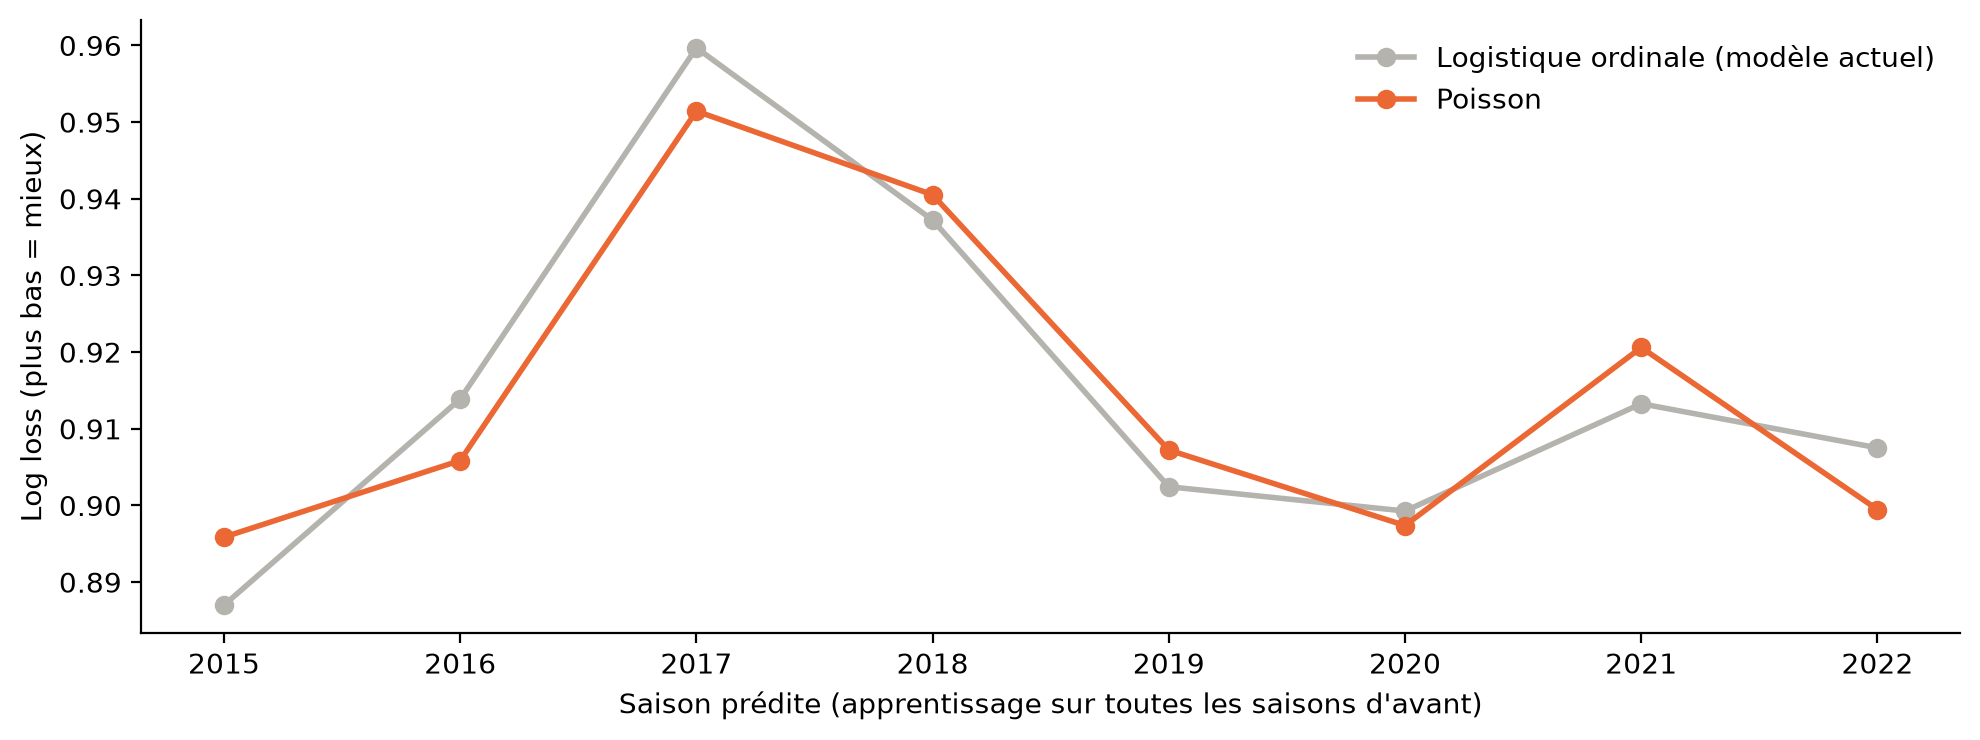

Validation glissante : 8 saisons, 994 matchs
MAE des buts (par équipe) : Poisson 0.983 | DummyRegressor 1.111


,log loss,RPS,accuracy,balanced accuracy,saisons où Poisson fait mieux
modèle,,,,,
Poisson,0.9148,0.1869,59.1%,48.9%,—
Logistique ordinale (modèle actuel),0.9151,0.1868,59.3%,48.7%,4 / 8
Dummy (fréquences passées),1.0536,0.2353,45.9%,33.3%,8 / 8


In [5]:
def mesures(y_vrai, probas):
    # Log loss, RPS et accuracy, calculés à la main pour qu'on voie exactement ce qu'on mesure
    p = probas[ISSUES].to_numpy()
    vrai = pd.Series(y_vrai).map({issue: i for i, issue in enumerate(ISSUES)}).to_numpy()
    p_vrai = np.clip(p[np.arange(len(p)), vrai], 1e-15, 1)
    observe = np.eye(3)[vrai]
    rps = ((np.cumsum(p, axis=1)[:, :2] - np.cumsum(observe, axis=1)[:, :2]) ** 2).sum(axis=1) / 2
    predit = p.argmax(axis=1)
    return {'log loss': -np.log(p_vrai).mean(), 'RPS': rps.mean(), 'accuracy': (predit == vrai).mean(),
            'balanced accuracy': balanced_accuracy_score(vrai, predit)}

def mae_buts(masque_appr, masque_eval):
    # MAE des buts par équipe : Poisson contre DummyRegressor (moyenne de l'apprentissage, un par côté)
    _, l_d, l_e, _ = predire_poisson(masque_appr, masque_eval)
    appr, ev = g[masque_appr], g[masque_eval]
    reel = np.concatenate([ev['buts_dom'], ev['buts_ext']])
    dummy = np.concatenate([
        DummyRegressor(strategy='mean').fit(appr[['domicile']], appr['buts_dom']).predict(ev[['domicile']]),
        DummyRegressor(strategy='mean').fit(appr[['domicile']], appr['buts_ext']).predict(ev[['domicile']])])
    return {'MAE Poisson': mean_absolute_error(reel, np.concatenate([l_d, l_e])),
            'MAE DummyRegressor': mean_absolute_error(reel, dummy), 'matchs': masque_eval.sum()}

def predire_dummy(masque_appr, masque_eval):
    freq = g.loc[masque_appr, 'resultat'].value_counts(normalize=True)[ISSUES]
    return pd.DataFrame([freq.to_numpy()] * masque_eval.sum(), columns=ISSUES)

def predire_ordinale(masque_appr, masque_eval):
    ordre = ISSUES[::-1]                                          # extérieur < nul < domicile
    X = lambda d: np.column_stack([d['ecart_elo_complet'] / 100, d['domicile']])
    appr = g[masque_appr]
    rang = appr['resultat'].map({issue: i for i, issue in enumerate(ordre)}).to_numpy()
    ajust = OrderedModel(rang, X(appr), distr='logit').fit(method='bfgs', disp=False, maxiter=2000)
    p = ajust.model.predict(ajust.params, exog=X(g[masque_eval]))
    return pd.DataFrame(p, columns=ordre)[ISSUES]

MODELES = {
    'Dummy (fréquences passées)': predire_dummy,
    'Logistique ordinale (modèle actuel)': predire_ordinale,
    'Poisson': lambda a, e: predire_poisson(a, e)[0],
}

SAISONS_VALIDATION = range(2015, 2023)
lignes = []
for saison in SAISONS_VALIDATION:
    appr, a_predire = g['season'] < saison, g['season'] == saison
    for nom, predire in MODELES.items():
        lignes.append({'saison': saison, 'modèle': nom, 'matchs': a_predire.sum(),
                       **mesures(g.loc[a_predire, 'resultat'], predire(appr, a_predire))})
par_saison = pd.DataFrame(lignes)
mae_saisons = pd.DataFrame([mae_buts(g['season'] < s, g['season'] == s) for s in SAISONS_VALIDATION])

moyenne = lambda t: pd.Series({c: np.average(t[c], weights=t['matchs'])
                               for c in ['log loss', 'RPS', 'accuracy', 'balanced accuracy']})
glissante = par_saison.groupby('modèle').apply(moyenne).sort_values('log loss')
pivot = par_saison.pivot(index='saison', columns='modèle', values='log loss')
glissante['saisons où Poisson fait mieux'] = '—'
glissante.loc['Logistique ordinale (modèle actuel)', 'saisons où Poisson fait mieux'] = \
    f"{(pivot['Poisson'] < pivot['Logistique ordinale (modèle actuel)']).sum()} / {len(pivot)}"
glissante.loc['Dummy (fréquences passées)', 'saisons où Poisson fait mieux'] = \
    f"{(pivot['Poisson'] < pivot['Dummy (fréquences passées)']).sum()} / {len(pivot)}"

fig, ax = plt.subplots(figsize=(10, 3.8))
for nom, couleur in [('Logistique ordinale (modèle actuel)', GRIS), ('Poisson', ORANGE)]:
    ax.plot(pivot.index, pivot[nom], marker='o', color=couleur, linewidth=2, label=nom)
ax.set_xlabel("Saison prédite (apprentissage sur toutes les saisons d'avant)")
ax.set_ylabel('Log loss (plus bas = mieux)')
ax.legend(frameon=False)
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.show()
print(f"Validation glissante : {len(SAISONS_VALIDATION)} saisons, {par_saison.groupby('modèle')['matchs'].sum().iloc[0]} matchs")
print(f"MAE des buts (par équipe) : Poisson {np.average(mae_saisons['MAE Poisson'], weights=mae_saisons['matchs']):.3f} | "
      f"DummyRegressor {np.average(mae_saisons['MAE DummyRegressor'], weights=mae_saisons['matchs']):.3f}")
glissante.style.format({'log loss': '{:.4f}', 'RPS': '{:.4f}', 'accuracy': '{:.1%}', 'balanced accuracy': '{:.1%}'})

**Lecture :**
| Validation glissante (8 saisons, 994 matchs) | Log loss | RPS | Accuracy | Balanced accuracy |
|---|---|---|---|---|
| **Poisson** | **0,9148** | 0,1869 | 59,1 % | 48,9 % |
| Logistique ordinale (`MODEL_BASELINE`) | 0,9151 | 0,1868 | 59,3 % | 48,7 % |
| Dummy | 1,0536 | 0,2353 | 45,9 % | 33,3 % |

| Les buts (par équipe) | MAE |
|---|---|
| **Poisson** | **0,983 but** |
| `DummyRegressor` (moyenne) | 1,111 but |

- **Poisson et le modèle actuel sont à égalité** : 0,9148 contre 0,9151 de log loss, et Poisson fait mieux sur 4 saisons sur 8. Les deux utilisent la même information (l'écart d'Elo et le terrain), il est donc logique qu'ils trouvent le vainqueur aussi bien l'un que l'autre.
- **Les deux écrasent le Dummy**, sur les 8 saisons, y compris en balanced accuracy (49 % contre 33 %).
- **Sur les buts, Poisson se trompe 12 % de moins que le `DummyRegressor`** : 0,98 but d'erreur moyenne par équipe, contre 1,11. Une erreur proche d'un but paraît grande, mais un nombre de buts est un entier très variable : même en connaissant parfaitement le niveau des équipes, on ne peut pas descendre beaucoup plus bas.
- **Conclusion :** passer à Poisson ne coûte rien en précision. Ce qu'il apporte, ce sont les scores.

## 5. Test final sur 2023-2025

Le modèle apprend sur 2012-2022, puis prédit les 502 matchs de 2023 à 2025, qu'il n'a jamais vus. **On ne fait ce test qu'une fois** : on ne revient pas modifier le modèle après.

En plus des moyennes, on mesure si l'écart entre Poisson et le modèle actuel est **réel ou dû au hasard**. Pour ça, on fait un *bootstrap* : on retire 5 000 fois au hasard 502 matchs parmi les 502 (avec remise), et on recalcule l'écart à chaque fois. Si l'intervalle obtenu contient 0, les deux modèles sont à égalité.

In [6]:
avant_test, test = g['season'] <= 2022, g['season'] >= 2023
y_test = g.loc[test, 'resultat']

probas_test = {nom: predire(avant_test, test) for nom, predire in MODELES.items()}
proba_p, lam_dom_t, lam_ext_t, m_test = predire_poisson(avant_test, test)
resultats_test = pd.DataFrame({nom: mesures(y_test, p) for nom, p in probas_test.items()}).T

# Bootstrap apparié : écart de log loss Poisson − modèle actuel, match par match
def perte_par_match(probas):
    p = probas[ISSUES].to_numpy()
    vrai = y_test.map({issue: i for i, issue in enumerate(ISSUES)}).to_numpy()
    return -np.log(p[np.arange(len(p)), vrai])

ecart = perte_par_match(probas_test['Poisson']) - perte_par_match(probas_test['Logistique ordinale (modèle actuel)'])
rng = np.random.default_rng(GRAINE)
tirages = rng.integers(0, len(ecart), size=(5000, len(ecart)))
ecarts_boot = ecart[tirages].mean(axis=1)
ic_bas, ic_haut = np.percentile(ecarts_boot, [2.5, 97.5])

n_test = test.sum()
marge = 1.96 * np.sqrt(0.58 * 0.42 / n_test)
print(f"Matchs de test : {n_test} | marge d'erreur d'une accuracy autour de 58 % : ± {marge:.1%}")
print(f"Écart de log loss Poisson − modèle actuel : {ecart.mean():+.4f} "
      f"(intervalle à 95 % : {ic_bas:+.4f} à {ic_haut:+.4f})")
mae_test = mae_buts(avant_test, test)
print(f"MAE des buts (par équipe) : Poisson {mae_test['MAE Poisson']:.3f} | DummyRegressor {mae_test['MAE DummyRegressor']:.3f}")
resultats_test.style.format({'log loss': '{:.3f}', 'RPS': '{:.4f}', 'accuracy': '{:.1%}', 'balanced accuracy': '{:.1%}'})

Matchs de test : 502 | marge d'erreur d'une accuracy autour de 58 % : ± 4.3%
Écart de log loss Poisson − modèle actuel : -0.0014 (intervalle à 95 % : -0.0073 à +0.0035)
MAE des buts (par équipe) : Poisson 1.026 | DummyRegressor 1.136


,log loss,RPS,accuracy,balanced accuracy
Dummy (fréquences passées),1.020,0.2359,50.0%,33.3%
Logistique ordinale (modèle actuel),0.904,0.1936,58.2%,44.7%
Poisson,0.902,0.1932,58.6%,45.5%


**La matrice de confusion, et la question de l'atelier.** Le prof propose comme cible « victoire à domicile, oui ou non ». Notre modèle y répond directement : P(victoire domicile) est l'une de ses trois probabilités. On prédit « oui » quand elle dépasse 50 %. La baseline est un `DummyClassifier(strategy="most_frequent")` appris sur 2012-2022.

In [7]:
# 1. Matrice de confusion à 3 issues (règle : l'issue la plus probable)
vrai_t = y_test.to_numpy()
predit_t = proba_p[ISSUES].idxmax(axis=1).to_numpy()
matrice = pd.DataFrame(confusion_matrix(vrai_t, predit_t, labels=ISSUES),
                       index=[f'vrai : {i}' for i in ISSUES], columns=[f'prédit : {i}' for i in ISSUES])
print("Matrice de confusion à 3 issues (test 2023-2025, nombre de matchs) :")
display(matrice)
rappel = pd.Series(np.diag(matrice.to_numpy()) / matrice.sum(axis=1).to_numpy(), index=ISSUES)
print("Taux de réussite par issue (rappel) : " + ', '.join(f"{i} {v:.0%}" for i, v in rappel.items()))

# 2. La version binaire : victoire à domicile, oui ou non
y_bin = (y_test == 'Victoire domicile').to_numpy()
pred_bin = (proba_p['Victoire domicile'] > 0.5).to_numpy()
cible_appr = g.loc[avant_test, 'resultat'] == 'Victoire domicile'
dummy_bin = DummyClassifier(strategy='most_frequent').fit(g.loc[avant_test, ['domicile']], cible_appr)
pred_dummy_bin = dummy_bin.predict(g.loc[test, ['domicile']])
print(f"\nVersion binaire : {cible_appr.mean():.1%} de victoires à domicile en 2012-2022, "
      f"donc la classe majoritaire est « {'oui' if dummy_bin.predict(g.loc[test, ['domicile']].head(1))[0] else 'non'} »")
display(pd.DataFrame(confusion_matrix(y_bin, pred_bin, labels=[True, False]),
                     index=['vrai : oui', 'vrai : non'], columns=['prédit : oui', 'prédit : non']))
pd.DataFrame({
    'Dummy (classe majoritaire)': {'accuracy': (pred_dummy_bin == y_bin).mean(),
                                   'balanced accuracy': balanced_accuracy_score(y_bin, pred_dummy_bin)},
    'Poisson (P > 50 %)': {'accuracy': (pred_bin == y_bin).mean(),
                           'balanced accuracy': balanced_accuracy_score(y_bin, pred_bin)},
}).T.style.format('{:.1%}')

Matrice de confusion à 3 issues (test 2023-2025, nombre de matchs) :


,prédit : Victoire domicile,prédit : Nul,prédit : Victoire extérieur
vrai : Victoire domicile,201,0,50
vrai : Nul,56,0,30
vrai : Victoire extérieur,72,0,93


Taux de réussite par issue (rappel) : Victoire domicile 80%, Nul 0%, Victoire extérieur 56%

Version binaire : 46.7% de victoires à domicile en 2012-2022, donc la classe majoritaire est « non »


,prédit : oui,prédit : non
vrai : oui,147,104
vrai : non,56,195


,accuracy,balanced accuracy
Dummy (classe majoritaire),50.0%,50.0%
Poisson (P > 50 %),68.1%,68.1%


**Lecture :**
- **Le modèle ne prédit jamais le nul** : 0 nul trouvé sur 86. Même entre deux équipes de même niveau, la probabilité de nul plafonne vers 24 %, toujours en dessous de celle d'une victoire. Avec la règle « l'issue la plus probable », le nul ne sort donc jamais. C'est ce qui fait tomber la balanced accuracy à 45,5 %, alors que l'accuracy est de 58,6 %.
- **Sur les victoires, il est solide** : il trouve 80 % des victoires à domicile et 56 % des victoires à l'extérieur.
- **Pourquoi on ne « force » pas des nuls :** on pourrait prédire « nul » dès que sa probabilité dépasse un seuil, réglé sur la validation. La balanced accuracy monterait, mais au prix de victoires mal prédites. Et surtout, la simulation n'utilise pas ces prédictions : elle **tire** les scores selon les probabilités, et les nuls y apparaissent avec la bonne fréquence (section 6).
- **La question de l'atelier, « victoire à domicile oui/non »** : notre modèle y répond avec **68,1 %** d'accuracy et 68,1 % de balanced accuracy, contre 50,0 % pour le Dummy. La classe majoritaire de 2012-2022 est « non » (46,7 % de victoires à domicile seulement) : le Dummy prédit donc toujours « pas de victoire à domicile ». Prédire des scores ne nous a rien fait perdre sur la question de départ.

**Lecture :**
| Test (2023-2025, 502 matchs) | Log loss | RPS | Accuracy | Balanced accuracy | MAE des buts |
|---|---|---|---|---|---|
| **Poisson** | **0,902** | **0,1932** | **58,6 %** | **45,5 %** | **1,026** |
| Logistique ordinale (`MODEL_BASELINE`) | 0,904 | 0,1936 | 58,2 % | 44,7 % | — |
| Dummy / `DummyRegressor` | 1,020 | 0,2359 | 50,0 % | 33,3 % | 1,136 |

- **Le test confirme la validation** : Poisson est légèrement devant sur toutes les mesures, et très loin devant le Dummy.
- **Mais l'écart avec le modèle actuel n'est pas réel** : −0,0014 de log loss, avec un intervalle à 95 % de −0,0073 à +0,0035, qui contient 0. De même, 0,4 point d'accuracy représente 2 matchs sur 502, bien en dessous de la marge d'erreur (± 4,3 points).
- **Conclusion :** égalité sur le vainqueur. On garde Poisson pour ce qu'il ajoute.

## 6. Les scores prédits sont-ils réalistes ?

C'est la vraie question de ce notebook. Une bonne log loss dit que le modèle trouve le bon vainqueur ; elle ne dit pas que les **scores** sont crédibles. Or la simulation va s'en servir pour la différence de buts et les matchs aller-retour.

On compare, sur les 502 matchs de test, ce que le modèle prévoit à ce qui s'est passé :
1. le nombre moyen de buts ;
2. la fréquence de chaque score (1-0, 1-1, 2-1…) ;
3. la répartition du **nombre total de buts** et de la **différence de buts** ;
4. la **calibration** : quand le modèle annonce 60 % de victoire à domicile, l'équipe gagne-t-elle vraiment environ 6 fois sur 10 ?

In [8]:
reel = g.loc[test, ['buts_dom', 'buts_ext']].to_numpy().astype(int)

# 1. Buts moyens
buts = pd.DataFrame({'prévu': [lam_dom_t.mean(), lam_ext_t.mean()], 'réel': reel.mean(axis=0)},
                    index=['équipe qui reçoit', 'équipe qui se déplace'])
print("Buts moyens par match (test 2023-2025) :")
print(buts.round(2).to_string())

# 2. Fréquence des scores : moyenne des grilles prévues contre fréquence observée
grille_moy = m_test.mean(axis=0)
obs = np.zeros_like(grille_moy)
np.add.at(obs, (np.minimum(reel[:, 0], MAX_BUTS), np.minimum(reel[:, 1], MAX_BUTS)), 1)
obs /= len(reel)
freq_scores = pd.DataFrame([{'score': f'{i}-{j}', 'prévu (%)': grille_moy[i, j] * 100, 'réel (%)': obs[i, j] * 100}
                            for i in range(MAX_BUTS + 1) for j in range(MAX_BUTS + 1)])
freq_scores = freq_scores.sort_values('réel (%)', ascending=False).head(10).set_index('score')

# Score exact : le score le plus probable du modèle, contre la règle « toujours le score le plus fréquent »
score_predit = np.array([np.unravel_index(m.argmax(), m.shape) for m in m_test])
exact_modele = (score_predit == reel).all(axis=1).mean()
appr = g[avant_test]
plus_frequent = (appr['buts_dom'].astype(str) + '-' + appr['buts_ext'].astype(str)).value_counts().index[0]
exact_naif = ((g.loc[test, 'buts_dom'].astype(str) + '-' + g.loc[test, 'buts_ext'].astype(str)) == plus_frequent).mean()
print(f"\nScore exact trouvé : {exact_modele:.1%} des matchs (règle « toujours {plus_frequent} » : {exact_naif:.1%})")
print(f"Nuls : {issues_depuis_scores(m_test)['Nul'].mean():.1%} prévus en moyenne, {(y_test == 'Nul').mean():.1%} réels")
freq_scores.round(1)

Buts moyens par match (test 2023-2025) :
                       prévu  réel
équipe qui reçoit       1.65  1.87
équipe qui se déplace   1.29  1.41

Score exact trouvé : 9.8% des matchs (règle « toujours 1-1 » : 6.6%)
Nuls : 21.6% prévus en moyenne, 17.1% réels


,prévu (%),réel (%)
score,,
1-0,8.5,9.0
2-1,8.0,7.8
2-0,7.3,7.0
1-1,10.2,6.6
1-2,6.7,5.8
0-1,7.2,5.8
3-1,4.6,5.4
2-3,2.1,5.2
0-0,5.4,4.8


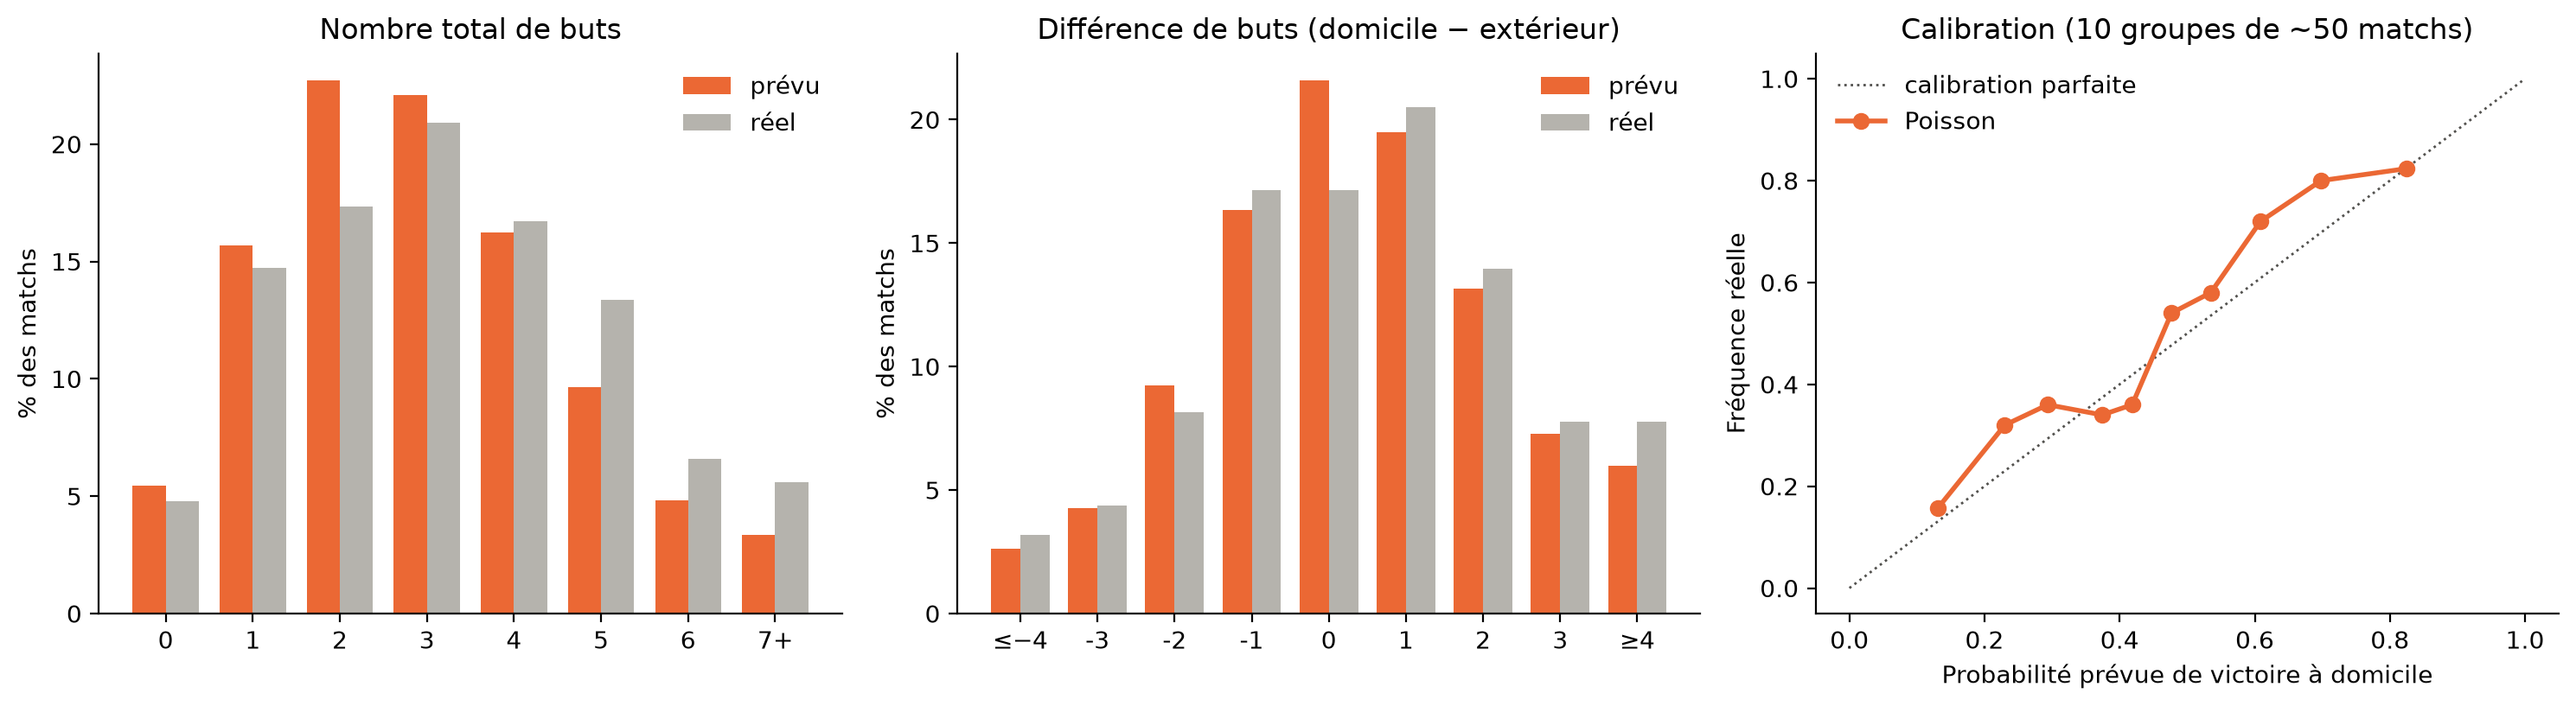

In [9]:
# 3. Total de buts et différence de buts : prévu contre réel
i, j = np.meshgrid(K, K, indexing='ij')
total_prevu = pd.Series(grille_moy.ravel()).groupby(np.minimum(i + j, 7).ravel()).sum()
total_reel = pd.Series(np.minimum(reel.sum(axis=1), 7)).value_counts(normalize=True).reindex(range(8), fill_value=0)
diff_prevu = pd.Series(grille_moy.ravel()).groupby(np.clip(i - j, -4, 4).ravel()).sum()
diff_reel = pd.Series(np.clip(reel[:, 0] - reel[:, 1], -4, 4)).value_counts(normalize=True).reindex(range(-4, 5), fill_value=0)

# 4. Calibration de la probabilité de victoire à domicile, par groupe de 10 % des matchs
calib = pd.DataFrame({'prévu': proba_p['Victoire domicile'].to_numpy(),
                      'réel': (y_test == 'Victoire domicile').to_numpy()})
calib['groupe'] = pd.qcut(calib['prévu'], 10, labels=False, duplicates='drop')
calib = calib.groupby('groupe').agg(prévu=('prévu', 'mean'), réel=('réel', 'mean'), matchs=('réel', 'size'))

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
largeur = 0.38
for ax, prevu, vrai, titre, etiquettes in [
    (axes[0], total_prevu, total_reel, 'Nombre total de buts', [str(k) for k in range(7)] + ['7+']),
    (axes[1], diff_prevu, diff_reel, 'Différence de buts (domicile − extérieur)', ['≤−4'] + [str(k) for k in range(-3, 4)] + ['≥4']),
]:
    x = np.arange(len(prevu))
    ax.bar(x - largeur / 2, prevu.to_numpy() * 100, largeur, color=ORANGE, label='prévu')
    ax.bar(x + largeur / 2, vrai.to_numpy() * 100, largeur, color=GRIS, label='réel')
    ax.set_xticks(x, etiquettes)
    ax.set_title(titre)
    ax.set_ylabel('% des matchs')
    ax.legend(frameon=False)
axes[2].plot([0, 1], [0, 1], color=ENCRE, linestyle=':', linewidth=1, label='calibration parfaite')
axes[2].plot(calib['prévu'], calib['réel'], marker='o', color=ORANGE, linewidth=2, label='Poisson')
axes[2].set_xlabel('Probabilité prévue de victoire à domicile')
axes[2].set_ylabel('Fréquence réelle')
axes[2].set_title('Calibration (10 groupes de ~50 matchs)')
axes[2].legend(frameon=False, loc='upper left')
for ax in axes:
    ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.show()

**Lecture :**
- **Le score exact** est trouvé dans **9,8 %** des matchs, contre 6,6 % pour la règle « toujours 1-1 ». Ça paraît peu, mais il y a des dizaines de scores possibles.
- **La forme des scores est juste** : 1-0, 2-1, 2-0, 3-0 et 0-0 sont prévus à moins d'un point de leur fréquence réelle. La **différence de buts** est proche de la réalité, sauf pour le 0 (le nul).
- **La calibration est bonne aux extrêmes** : quand le modèle annonce 15 % ou 80 % de victoire à domicile, c'est ce qui se passe. Au milieu (45 à 70 %), l'équipe qui reçoit gagne un peu plus souvent que prévu.
- **Deux défauts, liés entre eux :**
  1. **les buts sont sous-estimés** : 1,65 et 1,29 prévus, pour 1,87 et 1,41 réels. Le modèle prévoit trop de matchs à 2 buts (22,7 % contre 17,3 %) et pas assez à 5 buts ou plus ;
  2. **les nuls sont surestimés** : 21,6 % prévus, 17,1 % réels, et surtout le 1-1 (10,2 % contre 6,6 %).

  Moins de buts, c'est mécaniquement plus de nuls. La section suivante montre d'où vient ce manque de buts.

## 7. Depuis le nouveau format, on observe plus de buts

La section 6 montre que le modèle **sous-estime les buts** sur le test. On regarde saison par saison pour comprendre d'où ça vient.

> ⚠️ **Transparence :** c'est en regardant le test 2023-2025 (section 6) qu'on a repéré ce problème. Le test a donc servi à **orienter** une décision, ce qu'un test ne devrait pas faire. Pour rester honnêtes : les résultats des sections 5 et 6 concernent le modèle « Elo + terrain », choisi **avant** de regarder le test ; et la variable « nouveau format » n'est justifiée **que** par un test vers l'avant, sur une saison que le modèle n'avait pas vue (ci-dessous). Il n'existe pas de données plus récentes jamais vues : les matchs 2026-2027 ne sont pas dans le fichier.

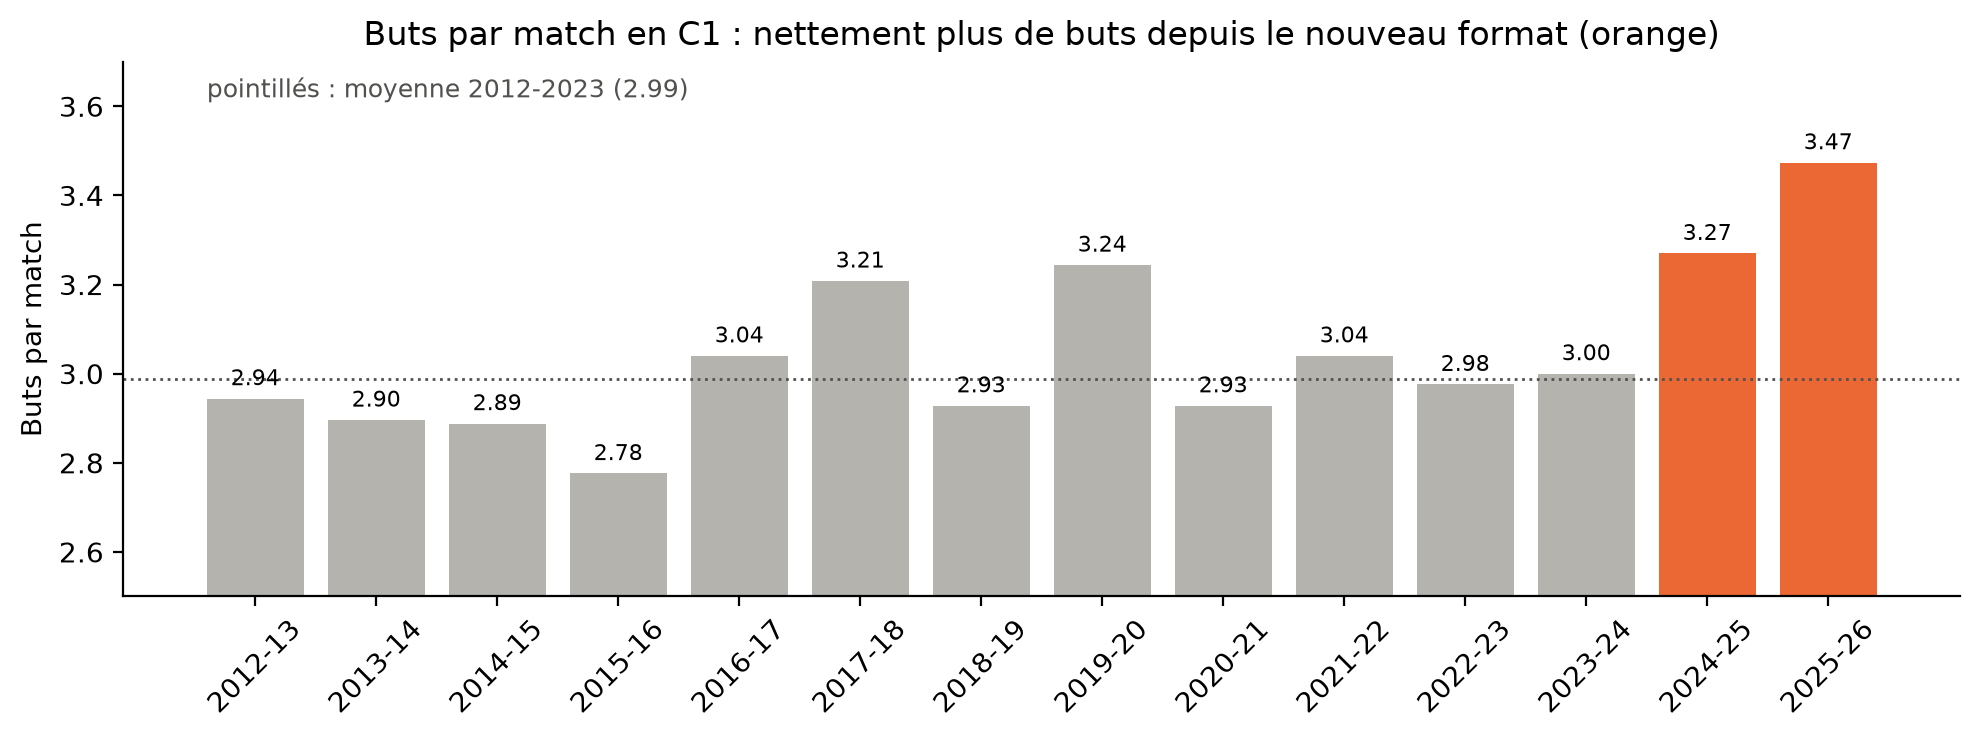

,buts par match,nuls,ecart_elo_moyen
season,,,
2020,2.93,19.2%,160
2021,3.04,20.8%,158
2022,2.98,20.8%,138
2023,3.00,21.6%,135
2024,3.27,13.8%,139
2025,3.47,17.6%,145


In [10]:
par_saison_buts = g.groupby('season').agg(dom=('buts_dom', 'mean'), ext=('buts_ext', 'mean'),
                                          nuls=('resultat', lambda r: (r == 'Nul').mean()),
                                          ecart_elo_moyen=('ecart_elo_complet', lambda e: e.abs().mean()))
par_saison_buts['buts par match'] = par_saison_buts['dom'] + par_saison_buts['ext']
avant = par_saison_buts.loc[:2023, 'buts par match'].mean()

fig, ax = plt.subplots(figsize=(10, 3.8))
couleurs = [ORANGE if s >= 2024 else GRIS for s in par_saison_buts.index]
ax.bar(par_saison_buts.index, par_saison_buts['buts par match'], color=couleurs)
ax.axhline(avant, color=ENCRE, linestyle=':', linewidth=1)
ax.text(2011.6, 3.62, f"pointillés : moyenne 2012-2023 ({avant:.2f})", fontsize=9, color=ENCRE)
for s, v in par_saison_buts['buts par match'].items():
    ax.text(s, v + 0.03, f"{v:.2f}", ha='center', fontsize=8)
ax.set_ylim(2.5, 3.7)
ax.set_xticks(par_saison_buts.index, [f"{s}-{str(s + 1)[2:]}" for s in par_saison_buts.index], rotation=45)
ax.set_ylabel('Buts par match')
ax.set_title('Buts par match en C1 : nettement plus de buts depuis le nouveau format (orange)')
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.show()
par_saison_buts[['buts par match', 'nuls', 'ecart_elo_moyen']].loc[2020:].style.format(
    {'buts par match': '{:.2f}', 'nuls': '{:.1%}', 'ecart_elo_moyen': '{:.0f}'})

**Lecture :**
- **Jusqu'en 2023-2024, le nombre de buts est stable** : entre 2,78 et 3,24 par match, 2,99 en moyenne.
- **Depuis le nouveau format, il saute** : **3,27** en 2024-2025, puis **3,47** en 2025-2026. Les nuls baissent en même temps (13,8 % et 17,6 %, contre environ 21 % avant).
- **Ce n'est pas dû à des matchs plus déséquilibrés** : l'écart d'Elo moyen entre les deux équipes n'a pas augmenté (139 et 145 points, contre 135 à 160 avant). À niveau égal, on marque simplement plus.
- **Le modèle ne peut pas le voir** : il moyenne toutes les saisons, dont 12 dans l'ancien format. C'est pour ça qu'il sous-estime les buts sur le test, qui contient 2 saisons du nouveau format sur 3.

**Le test honnête :** on apprend sur toutes les saisons jusqu'à 2024-2025, la seule saison du nouveau format connue à ce moment-là, puis on prédit **2025-2026**, que le modèle n'a jamais vue. On compare le modèle sans et avec la variable « nouveau format ».

Pour juger les **scores**, on ajoute une mesure : la **log loss des buts**, la même idée que la log loss, appliquée au nombre de buts de chaque équipe. Plus bas = des scores mieux prévus.

In [11]:
from scipy.stats import poisson

def log_loss_buts(lam_dom, lam_ext, d):
    # Log loss des buts réellement marqués par les deux équipes, moyenne par match
    return -(poisson.logpmf(d['buts_dom'], lam_dom) + poisson.logpmf(d['buts_ext'], lam_ext)).mean()

appr_25, saison_25 = g['season'] <= 2024, g['season'] == 2025
d25 = g[saison_25]
comparaison_format = {}
for nom, variables in [('Poisson (Elo + terrain)', VARIABLES), ('Poisson + nouveau format', VARIABLES + ['nouveau_format'])]:
    probas, l_d, l_e, _ = predire_poisson(appr_25, saison_25, variables)
    comparaison_format[nom] = {**mesures(d25['resultat'], probas), 'log loss des buts': log_loss_buts(l_d, l_e, d25),
                               'buts prévus': (l_d + l_e).mean(), 'nuls prévus': probas['Nul'].mean()}
comparaison_format = pd.DataFrame(comparaison_format).T
comparaison_format['buts réels'] = (d25['buts_dom'] + d25['buts_ext']).mean()
comparaison_format['nuls réels'] = (d25['resultat'] == 'Nul').mean()
print(f"Prédiction de la saison 2025-2026 ({saison_25.sum()} matchs), apprentissage sur 2012-2024")
comparaison_format[['log loss', 'RPS', 'log loss des buts', 'buts prévus', 'buts réels', 'nuls prévus', 'nuls réels']].style.format(
    {'log loss': '{:.4f}', 'RPS': '{:.4f}', 'log loss des buts': '{:.4f}', 'buts prévus': '{:.2f}', 'buts réels': '{:.2f}',
     'nuls prévus': '{:.1%}', 'nuls réels': '{:.1%}'})

Prédiction de la saison 2025-2026 (188 matchs), apprentissage sur 2012-2024


,log loss,RPS,log loss des buts,buts prévus,buts réels,nuls prévus,nuls réels
Poisson (Elo + terrain),0.9320,0.1998,3.3045,2.98,3.47,21.4%,17.6%
Poisson + nouveau format,0.9304,0.1996,3.2730,3.27,3.47,20.0%,17.6%


**Lecture :**
| Prédiction de 2025-2026 (188 matchs) | Log loss | Log loss des buts | Buts prévus | Nuls prévus |
|---|---|---|---|---|
| Poisson (Elo + terrain) | 0,9320 | 3,3045 | 2,98 | 21,4 % |
| **Poisson + nouveau format** | **0,9304** | **3,2730** | **3,27** | **20,0 %** |
| *Réel* | | | *3,47* | *17,6 %* |

- **La variable « nouveau format » améliore tout** : les probabilités du vainqueur, les scores (log loss des buts : 3,273 contre 3,305) et le niveau de buts (3,27 prévus contre 2,98, pour 3,47 réels).
- **Elle ne corrige pas tout** : appris sur une seule saison, l'effet reste un peu en dessous de la réalité. Le modèle final l'apprend sur les deux saisons du nouveau format, et l'estime plus fort (× 1,14 au lieu de × 1,11).
- **Pourquoi c'est un test honnête :** l'effet a été appris sur 2024-2025 et jugé sur 2025-2026, une saison que le modèle n'avait pas vue.
- **Décision :** on garde la variable dans le modèle final. Elle est connue avant le match (on sait dans quel format on joue), et 2026-2027 est dans le nouveau format.

## 8. La forme récente apporte-t-elle quelque chose ?

La **forme récente** fait partie des variables proposées par le prof. Loan la calcule dans `v2_forme.ipynb` : l'écart, entre les deux équipes, de points moyens par match sur leurs 5 derniers matchs officiels, joués **strictement avant** la date du match (`ecart_forme_5`, fichier `output/forme_par_match.csv`).

**La règle, fixée avant de voir le résultat :** on garde la variable seulement si elle améliore la log loss moyenne de la validation glissante **et** si elle fait mieux sur **au moins 5 saisons sur 8**. Sinon, on la rejette : une variable de plus qui n'aide pas ajoute du bruit et une source d'erreur.

Si le fichier n'existe pas encore, cette section est sautée sans erreur.

In [12]:
CHEMIN_FORME = '../output/forme_par_match.csv'
garder_forme = False
if os.path.exists(CHEMIN_FORME):
    forme = pd.read_csv(CHEMIN_FORME, encoding='utf-8-sig').set_index('game_id')['ecart_forme_5']
    g['ecart_forme_5'] = g['game_id'].map(forme)
    print(f"Forme récente chargée : {g['ecart_forme_5'].notna().mean():.1%} des matchs renseignés "
          f"(les manquants sont remplacés par la médiane de l'apprentissage, dans le Pipeline)")
    print(f"Corrélation avec l'écart d'Elo : {g[['ecart_forme_5', 'ecart_elo_complet']].corr().iloc[0, 1]:.2f}")
    comparaison_forme = []
    for saison in SAISONS_VALIDATION:
        appr, a_predire = g['season'] < saison, g['season'] == saison
        sans = mesures(g.loc[a_predire, 'resultat'], predire_poisson(appr, a_predire)[0])['log loss']
        avec = mesures(g.loc[a_predire, 'resultat'], predire_poisson(appr, a_predire, VARIABLES + ['ecart_forme_5'])[0])['log loss']
        comparaison_forme.append({'saison': saison, 'matchs': a_predire.sum(), 'sans la forme': sans, 'avec la forme': avec})
    comparaison_forme = pd.DataFrame(comparaison_forme).set_index('saison')
    moy_sans = np.average(comparaison_forme['sans la forme'], weights=comparaison_forme['matchs'])
    moy_avec = np.average(comparaison_forme['avec la forme'], weights=comparaison_forme['matchs'])
    nb_mieux = (comparaison_forme['avec la forme'] < comparaison_forme['sans la forme']).sum()
    garder_forme = (moy_avec < moy_sans) and (nb_mieux >= 5)
    print(f"Log loss moyenne : sans {moy_sans:.4f} | avec {moy_avec:.4f} | meilleure sur {nb_mieux} saisons sur 8")
    print("Décision :", "on GARDE la forme récente" if garder_forme else "on REJETTE la forme récente")
    display(comparaison_forme.round(4))
else:
    print(f"{CHEMIN_FORME} n'existe pas encore (travail de Loan) : section sautée, le modèle reste sans la forme récente.")

../output/forme_par_match.csv n'existe pas encore (travail de Loan) : section sautée, le modèle reste sans la forme récente.


**Lecture :**
**En attente du fichier de Loan.** La section est prête : dès que `output/forme_par_match.csv` existe, elle compare le modèle avec et sans la forme, saison par saison, et applique la règle fixée à l'avance.

**Ce qu'on peut déjà anticiper :** un calcul rapide, fait hors du dépôt avec une définition proche, donnait une log loss **identique** avec et sans la forme (0,9148), meilleure sur 4 saisons sur 8 seulement, avec une corrélation de 0,42 avec l'écart d'Elo. C'est logique : l'Elo est mis à jour après chaque match, c'est déjà une forme lissée. La variable serait donc probablement **rejetée**. La décision officielle sera prise avec le fichier de Loan.

## 9. Le modèle final et ce qu'il a appris

Le modèle est validé. On l'entraîne maintenant sur **toutes les saisons** (2012-2026), test compris, pour qu'il profite des 1 871 matchs, avec les trois variables : écart d'Elo, terrain et nouveau format. C'est cette version qui sert pour 2026-2027.

Buts attendus entre deux équipes de même niveau, sur terrain neutre, nouveau format : 1.57
Nouveau format : buts attendus × 1.142 (IC 95 % : × 1.073 à × 1.216)
+100 points d'Elo d'avance : buts attendus × 1.221 (IC 95 % : × 1.204 à × 1.238)
Recevoir plutôt que jouer sur terrain neutre : buts attendus × 1.137
Recevoir plutôt que se déplacer : buts attendus × 1.293


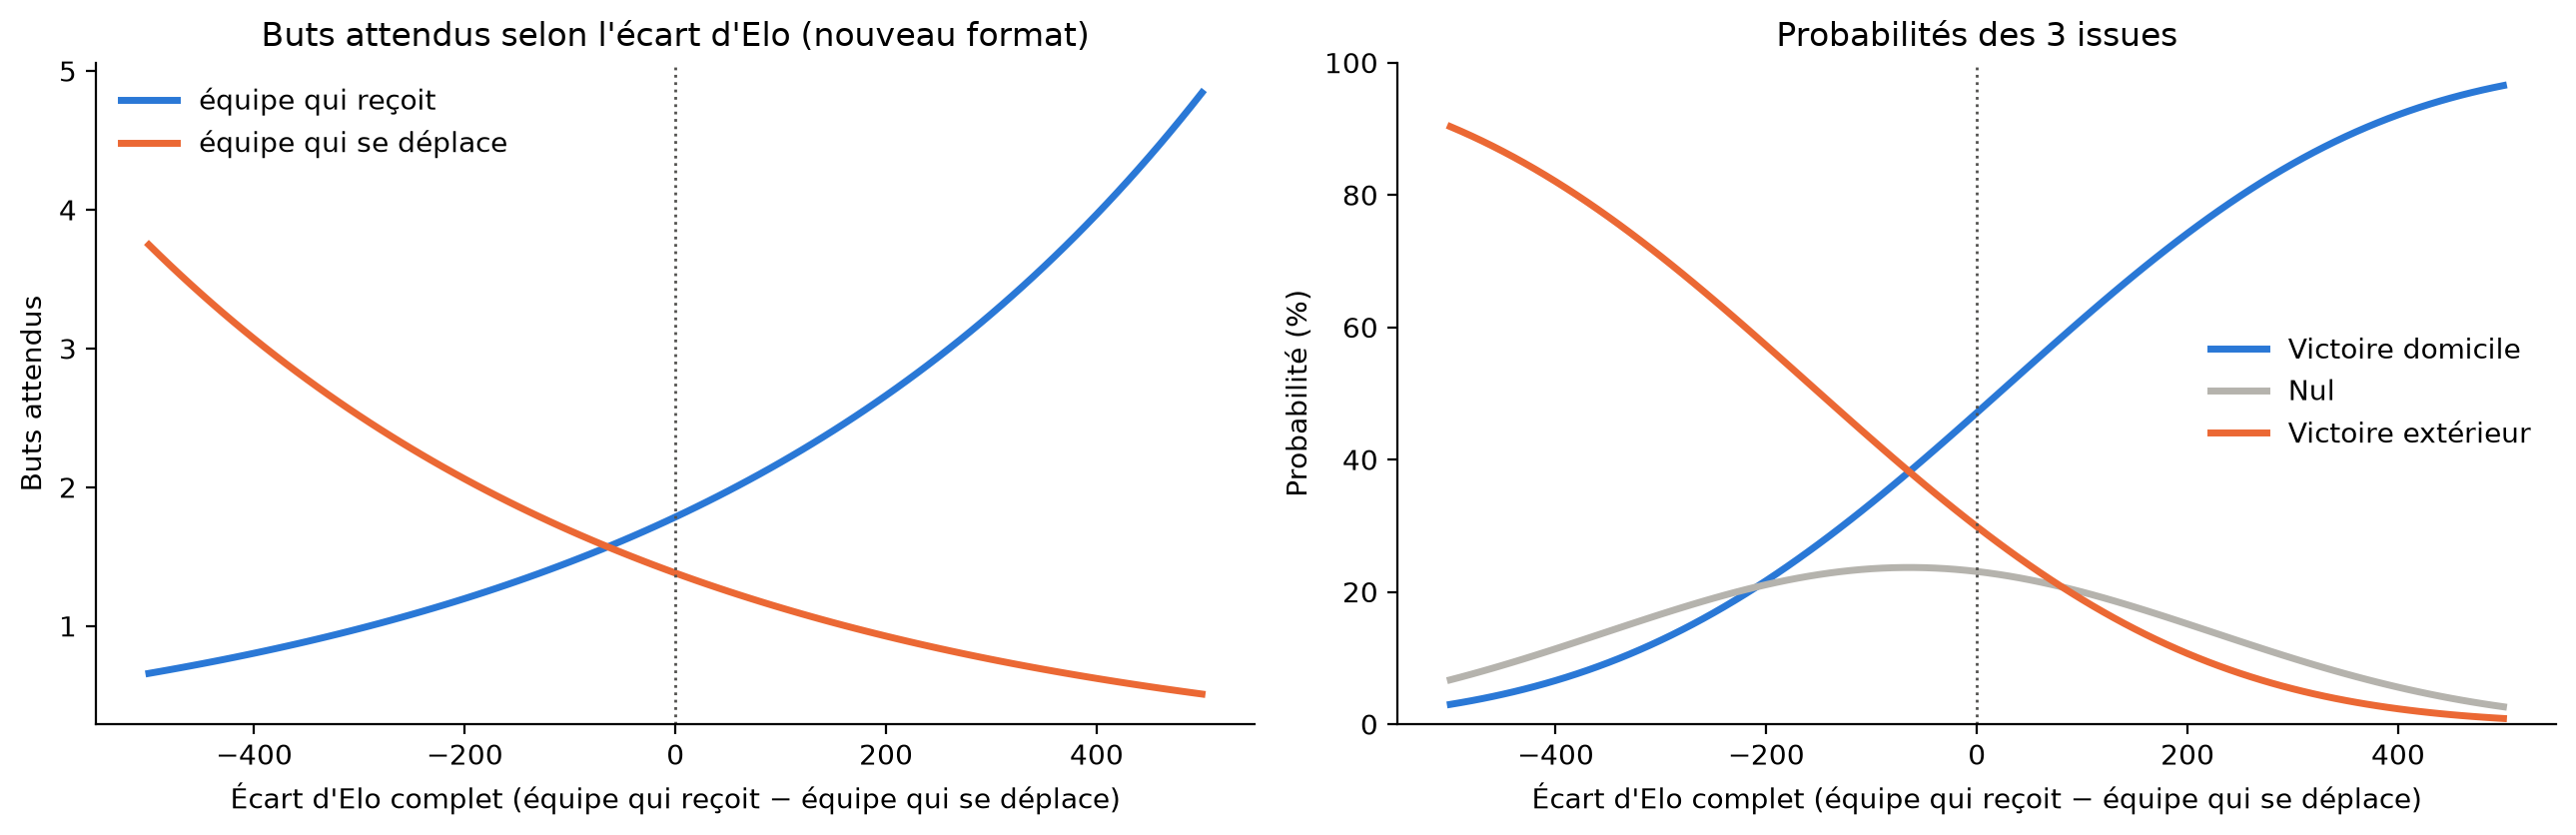

,coefficient,IC 95 % bas,IC 95 % haut
constante,0.3181,0.2869,0.3494
écart d'Elo (par 100 points),0.1996,0.1859,0.2133
terrain,0.1283,0.1021,0.1546
nouveau format,0.1331,0.0708,0.1954


In [13]:
VARIABLES_FINALES = VARIABLES + ['nouveau_format']
if garder_forme:
    print("⚠️ La forme récente améliore le modèle : il faudra l'ajouter à l'export, et la simulation devra la calculer.")
final = entrainer_poisson(g, VARIABLES_FINALES)
coefs = coefficients(final, VARIABLES_FINALES)

# Les intervalles de confiance viennent de statsmodels, qui ajuste exactement le même modèle
lignes_tout = lignes_equipes(g)
verification = sm.GLM(lignes_tout['buts'], sm.add_constant(lignes_tout[VARIABLES_FINALES]),
                      family=sm.families.Poisson()).fit()
assert np.allclose(verification.params[coefs.index], coefs, atol=1e-4), "scikit-learn et statsmodels ne trouvent pas le même modèle"
ic = verification.conf_int()

lecture = pd.DataFrame({
    'coefficient': coefs, 'IC 95 % bas': ic[0], 'IC 95 % haut': ic[1],
}).rename(index={'const': 'constante', 'ecart_100': 'écart d\'Elo (par 100 points)', 'terrain': 'terrain',
                 'nouveau_format': 'nouveau format'})
print(f"Buts attendus entre deux équipes de même niveau, sur terrain neutre, nouveau format : "
      f"{np.exp(coefs['const'] + coefs['nouveau_format']):.2f}")
print(f"Nouveau format : buts attendus × {np.exp(coefs['nouveau_format']):.3f} "
      f"(IC 95 % : × {np.exp(ic.loc['nouveau_format', 0]):.3f} à × {np.exp(ic.loc['nouveau_format', 1]):.3f})")
print(f"+100 points d'Elo d'avance : buts attendus × {np.exp(coefs['ecart_100']):.3f} "
      f"(IC 95 % : × {np.exp(ic.loc['ecart_100', 0]):.3f} à × {np.exp(ic.loc['ecart_100', 1]):.3f})")
print(f"Recevoir plutôt que jouer sur terrain neutre : buts attendus × {np.exp(coefs['terrain']):.3f}")
print(f"Recevoir plutôt que se déplacer : buts attendus × {np.exp(2 * coefs['terrain']):.3f}")

# Ce que le modèle a appris, selon l'écart d'Elo
ecarts = np.arange(-500, 501, 10, dtype=float)
grille = pd.DataFrame({'ecart_elo_complet': ecarts, 'domicile': 1, 'nouveau_format': 1})
l_d, l_e = buts_attendus_matchs(final, grille, VARIABLES_FINALES)
p_grille = issues_depuis_scores(matrices_scores(l_d, l_e))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.3))
ax1.plot(ecarts, l_d, color=BLEU, linewidth=2.5, label='équipe qui reçoit')
ax1.plot(ecarts, l_e, color=ORANGE, linewidth=2.5, label='équipe qui se déplace')
ax1.set_ylabel('Buts attendus')
ax1.set_title('Buts attendus selon l\'écart d\'Elo (nouveau format)')
for issue, couleur in zip(ISSUES, [BLEU, GRIS, ORANGE]):
    ax2.plot(ecarts, p_grille[issue] * 100, color=couleur, linewidth=2.5, label=issue)
ax2.set_ylabel('Probabilité (%)')
ax2.set_ylim(0, 100)
ax2.set_title('Probabilités des 3 issues')
for ax in (ax1, ax2):
    ax.axvline(0, color=ENCRE, linewidth=1, linestyle=':')
    ax.set_xlabel("Écart d'Elo complet (équipe qui reçoit − équipe qui se déplace)")
    ax.legend(frameon=False)
    ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.show()
lecture.round(4)

**Lecture :**
| Ce que le modèle a appris (1 871 matchs) | Effet sur les buts attendus | Intervalle à 95 % |
|---|---|---|
| +100 points d'Elo d'avance | **× 1,22** (+22 %) | × 1,20 à × 1,24 |
| Recevoir plutôt que se déplacer | **× 1,29** (+29 %) | |
| Recevoir plutôt que jouer sur terrain neutre | × 1,14 | |
| Nouveau format | **× 1,14** (+14 %) | × 1,07 à × 1,22 |

- **Deux équipes de même niveau, sur terrain neutre, dans le nouveau format, marquent 1,57 but chacune.**
- **L'Elo est de loin le facteur le plus fort** : 300 points d'écart multiplient les buts par 1,8 d'un côté et les divisent par 1,8 de l'autre.
- **Le nul plafonne à environ 24 %**, quand les deux équipes sont de même niveau, et baisse vite dès que l'écart grandit.
- **Les coefficients bougent très peu** entre le modèle appris sur 2012-2022 et le modèle final : le modèle est stable.

## 10. Export pour l'application et la simulation

On sauvegarde les **4 coefficients** (des nombres), pas l'objet Python : l'application et la simulation n'ont besoin que de `numpy`.

Quatre fonctions, à copier telles quelles :

| Fonction | Ce qu'elle renvoie | Pour qui |
|---|---|---|
| `buts_attendus(p, ecart_elo, domicile, minutes)` | les buts attendus des deux équipes | tout le monde |
| `matrice_scores(p, ecart_elo, domicile, minutes)` | la probabilité de chaque score, de 0-0 à 10-10 | l'application (score le plus probable) |
| `probas_match(p, ecart_elo, domicile)` | victoire, nul, défaite | l'application |
| `tirer_score(p, ecart_elo, domicile, minutes, rng)` | un score tiré au hasard, par exemple (2, 1) | la simulation |

**Conventions :** `ecart_elo` = Elo complet de l'équipe qui reçoit − Elo complet de l'autre ; `domicile = 1` si elle reçoit vraiment, `0` sur terrain neutre (la finale). `minutes = 30` donne les buts attendus d'une **prolongation** (le modèle répartit les buts uniformément sur le match). `nouveau_format = 1` par défaut : c'est le cas de toutes les saisons depuis 2024-2025.

In [14]:
parametres = {
    'type': 'poisson',
    'intercept': float(coefs['const']),
    'coef_ecart_100': float(coefs['ecart_100']),
    'coef_terrain': float(coefs['terrain']),
    'coef_nouveau_format': float(coefs['nouveau_format']),
    'max_buts': MAX_BUTS,
    'issues': ISSUES,
    'variables': ['ecart_elo_complet', 'domicile', 'nouveau_format'],
    'entraine_sur': f"{g['season'].min()}-{g['season'].max()} ({len(g)} matchs)",
}

def buts_attendus(p, ecart_elo, domicile=1, minutes=90, nouveau_format=1):
    # Buts attendus (équipe qui reçoit, équipe qui se déplace)
    niveau = p['intercept'] + p['coef_nouveau_format'] * nouveau_format
    z = p['coef_ecart_100'] * ecart_elo / 100 + p['coef_terrain'] * domicile
    duree = minutes / 90
    return float(np.exp(niveau + z) * duree), float(np.exp(niveau - z) * duree)

def matrice_scores(p, ecart_elo, domicile=1, minutes=90):
    # m[i, j] = probabilité que l'équipe qui reçoit marque i buts et l'autre j
    l_dom, l_ext = buts_attendus(p, ecart_elo, domicile, minutes)
    k = np.arange(p['max_buts'] + 1)
    fact = np.array([factorial(n) for n in k], dtype=float)
    m = np.outer(np.exp(-l_dom) * l_dom ** k / fact, np.exp(-l_ext) * l_ext ** k / fact)
    return m / m.sum()

def probas_match(p, ecart_elo, domicile=1):
    m = matrice_scores(p, ecart_elo, domicile)
    return {'Victoire domicile': float(np.tril(m, -1).sum()), 'Nul': float(np.trace(m)),
            'Victoire extérieur': float(np.triu(m, 1).sum())}

def tirer_score(p, ecart_elo, domicile=1, minutes=90, rng=None):
    rng = rng if rng is not None else np.random.default_rng()
    l_dom, l_ext = buts_attendus(p, ecart_elo, domicile, minutes)
    return int(rng.poisson(l_dom)), int(rng.poisson(l_ext))

# Vérifications
verif = pd.DataFrame({'ecart_elo_complet': [250.0, -120.0, 0.0], 'domicile': [1, 1, 0], 'nouveau_format': [1, 1, 1]})
attendu = issues_depuis_scores(matrices_scores(*buts_attendus_matchs(final, verif, VARIABLES_FINALES)))
for k, ligne in verif.iterrows():
    obtenu = probas_match(parametres, ligne['ecart_elo_complet'], ligne['domicile'])
    assert all(abs(obtenu[i] - attendu.loc[k, i]) < 1e-9 for i in ISSUES)
    assert abs(sum(obtenu.values()) - 1) < 1e-12
rng = np.random.default_rng(GRAINE)
tirages = np.array([tirer_score(parametres, 250.0, 1, rng=rng) for _ in range(100_000)])
assert np.allclose(tirages.mean(axis=0), buts_attendus(parametres, 250.0, 1), atol=0.02)
l90, l30 = buts_attendus(parametres, 0, 0), buts_attendus(parametres, 0, 0, minutes=30)
assert abs(l30[0] - l90[0] / 3) < 1e-12

os.makedirs('../output', exist_ok=True)
joblib.dump(parametres, '../output/modele_scores.joblib')
print("Vérifications OK. Modèle sauvegardé : output/modele_scores.joblib")
print(f"Exemple, +250 d'Elo à domicile : {buts_attendus(parametres, 250.0, 1)[0]:.2f} – "
      f"{buts_attendus(parametres, 250.0, 1)[1]:.2f} buts attendus, "
      + ', '.join(f"{i} {v:.1%}" for i, v in probas_match(parametres, 250.0, 1).items()))

Vérifications OK. Modèle sauvegardé : output/modele_scores.joblib
Exemple, +250 d'Elo à domicile : 2.94 – 0.84 buts attendus, Victoire domicile 79.8%, Nul 12.5%, Victoire extérieur 7.7%


## 11. Prédictions de la phase de ligue 2026-2027

On applique le modèle final aux **144 matchs officiels** de la phase de ligue (calendrier de `v2_participants.ipynb`), avec l'Elo complet des 36 clubs **avant le 8 septembre 2026**. Les résultats déjà joués ne sont pas utilisés : c'est une prévision faite avant le début de la compétition.

Pour chaque match : les buts attendus, le score le plus probable et les 3 probabilités. Le fichier `output/predictions_phase_ligue_2026.csv` sert à l'application et sert de point de départ à la simulation.

In [15]:
calendrier = pd.read_csv('../output/calendrier_2026.csv', encoding='utf-8-sig', parse_dates=['date'])
elo = pd.read_csv('../output/elo_participants_2026.csv').set_index('club_id')['elo_complet']

matchs = (calendrier[calendrier['lieu'] == 'domicile']
          .rename(columns={'nom_uefa': 'domicile_nom', 'adversaire_uefa': 'exterieur_nom'})
          [['match_id', 'journee', 'date', 'domicile_club_id', 'domicile_nom', 'exterieur_club_id', 'exterieur_nom']]
          .sort_values(['journee', 'match_id']).reset_index(drop=True))
assert len(matchs) == 144 and matchs[['domicile_club_id', 'exterieur_club_id']].isin(elo.index).all().all()

matchs['elo_domicile'] = matchs['domicile_club_id'].map(elo)
matchs['elo_exterieur'] = matchs['exterieur_club_id'].map(elo)
matchs['ecart_elo'] = matchs['elo_domicile'] - matchs['elo_exterieur']
lam = matchs['ecart_elo'].apply(lambda e: buts_attendus(parametres, e, 1))
matchs['buts_attendus_domicile'], matchs['buts_attendus_exterieur'] = lam.str[0], lam.str[1]
issues = pd.DataFrame([probas_match(parametres, e, 1) for e in matchs['ecart_elo']])
matchs['p_victoire_domicile'], matchs['p_nul'], matchs['p_victoire_exterieur'] = issues[ISSUES].to_numpy().T
matchs['score_le_plus_probable'] = [
    '{}-{}'.format(*np.unravel_index(matrice_scores(parametres, e, 1).argmax(), (MAX_BUTS + 1,) * 2))
    for e in matchs['ecart_elo']]
assert np.allclose(matchs[['p_victoire_domicile', 'p_nul', 'p_victoire_exterieur']].sum(axis=1), 1)

matchs.to_csv('../output/predictions_phase_ligue_2026.csv', index=False, encoding='utf-8-sig')
print(f"{len(matchs)} matchs prédits : output/predictions_phase_ligue_2026.csv")

affichage = lambda d: (d.assign(match=d['domicile_nom'] + ' – ' + d['exterieur_nom'],
                                buts_attendus=d['buts_attendus_domicile'].round(2).astype(str) + ' – '
                                              + d['buts_attendus_exterieur'].round(2).astype(str))
                        .set_index('match')[['journee', 'buts_attendus', 'score_le_plus_probable',
                                             'p_victoire_domicile', 'p_nul', 'p_victoire_exterieur']])
format_p = {c: '{:.0%}' for c in ['p_victoire_domicile', 'p_nul', 'p_victoire_exterieur']}
print("Les 8 plus grosses affiches (somme des deux Elo) :")
affichage(matchs.assign(s=matchs['elo_domicile'] + matchs['elo_exterieur']).nlargest(8, 's')).style.format(format_p)

144 matchs prédits : output/predictions_phase_ligue_2026.csv
Les 8 plus grosses affiches (somme des deux Elo) :


,journee,buts_attendus,score_le_plus_probable,p_victoire_domicile,p_nul,p_victoire_exterieur
match,,,,,,
Bayern München – Arsenal,3,1.61 – 1.54,1-1,40%,24%,37%
FC Barcelona – Man City,6,1.72 – 1.43,1-1,44%,23%,32%
Arsenal – Real Madrid,6,2.15 – 1.15,2-1,60%,20%,20%
Man City – Paris,2,2.05 – 1.2,2-1,57%,21%,22%
Paris – FC Barcelona,3,1.62 – 1.53,1-1,40%,24%,36%
Real Madrid – Inter,1,1.75 – 1.41,1-1,46%,23%,31%
Arsenal – Borussia Dortmund,5,2.55 – 0.97,2-0,72%,16%,12%
Man United – Bayern München,7,1.51 – 1.63,1-1,36%,24%,41%


**La difficulté du calendrier, club par club.** Deux clubs de même niveau n'ont pas les mêmes chances s'ils n'ont pas les mêmes adversaires. On mesure, pour chaque club :
- l'**Elo moyen de ses 8 adversaires** ;
- ses **points attendus** sur les 8 matchs : la somme, match par match, de 3 × P(victoire) + 1 × P(nul) ;
- l'**effet du tirage** : ses points attendus, moins ceux qu'il aurait obtenus contre 8 adversaires d'un niveau **moyen** (l'Elo moyen des 35 autres clubs), avec les mêmes matchs à domicile et à l'extérieur. Positif = tirage favorable.

Ce n'est pas encore la simulation (qui donnera le classement et les qualifiés), mais c'est un premier contrôle de cohérence.

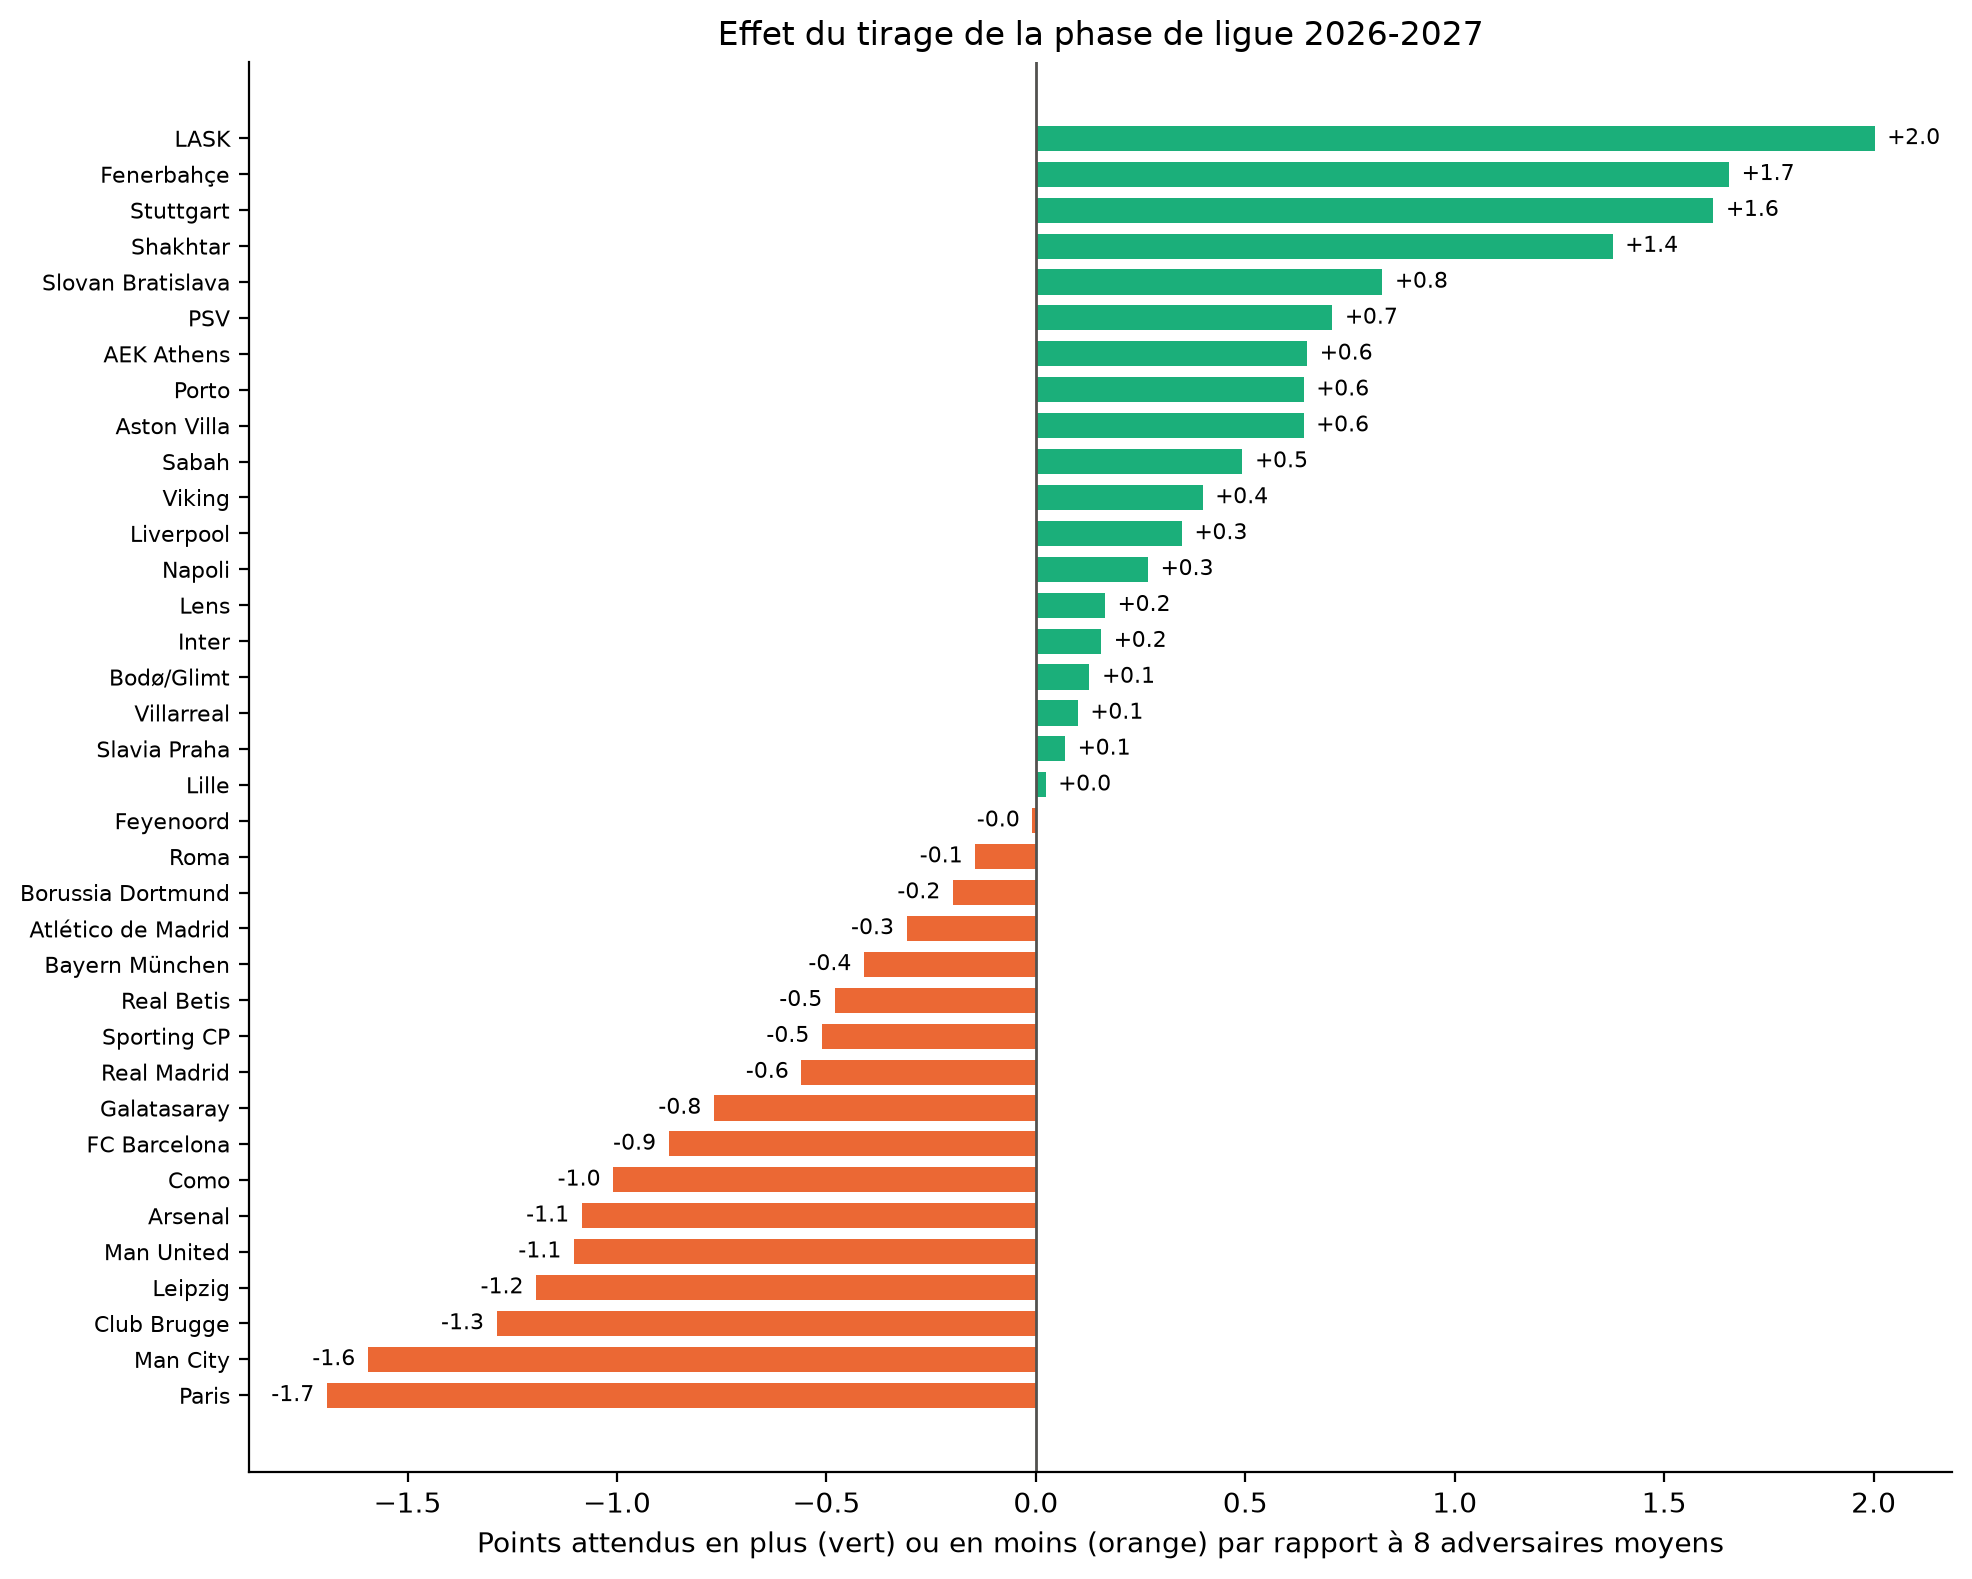

,rang_points,rang_elo,elo,elo_moyen_adversaires,points_attendus,diff_buts_attendue,effet_tirage
club,,,,,,,
Arsenal,1,1,2025,1765.0,18.0,14.6,-1.1
Bayern München,2,3,1972,1737.0,17.3,13.2,-0.4
Inter,3,5,1943,1728.0,17.0,11.8,0.2
FC Barcelona,4,4,1970,1775.0,16.7,10.4,-0.9
Man City,5,2,1989,1804.0,16.5,9.8,-1.6
Real Madrid,6,6,1932,1754.0,16.0,9.8,-0.6
Liverpool,7,8,1895,1741.0,15.8,8.1,0.3
Aston Villa,8,10,1860,1726.0,14.9,7.2,0.6
Paris,9,7,1920,1784.0,14.5,7.9,-1.7


In [16]:
def points_attendus(p_issues, recoit):
    return 3 * p_issues['Victoire domicile' if recoit else 'Victoire extérieur'] + p_issues['Nul']

vue = pd.concat([
    pd.DataFrame({'club': matchs['domicile_nom'], 'elo': matchs['elo_domicile'], 'elo_adversaire': matchs['elo_exterieur'],
                  'recoit': True, 'points': 3 * matchs['p_victoire_domicile'] + matchs['p_nul'],
                  'buts_pour': matchs['buts_attendus_domicile'], 'buts_contre': matchs['buts_attendus_exterieur']}),
    pd.DataFrame({'club': matchs['exterieur_nom'], 'elo': matchs['elo_exterieur'], 'elo_adversaire': matchs['elo_domicile'],
                  'recoit': False, 'points': 3 * matchs['p_victoire_exterieur'] + matchs['p_nul'],
                  'buts_pour': matchs['buts_attendus_exterieur'], 'buts_contre': matchs['buts_attendus_domicile']}),
])

# Les mêmes 8 matchs (même lieu), mais contre un adversaire de niveau moyen
somme_elo, nb_clubs = elo.sum(), len(elo)
vue['elo_moyen_autres'] = (somme_elo - vue['elo']) / (nb_clubs - 1)
vue['points_si_adversaire_moyen'] = [
    points_attendus(probas_match(parametres, (e - ref) if recoit else (ref - e), 1), recoit)
    for e, ref, recoit in zip(vue['elo'], vue['elo_moyen_autres'], vue['recoit'])]

par_club = vue.groupby('club').agg(elo=('elo', 'first'), elo_moyen_adversaires=('elo_adversaire', 'mean'),
                                   points_attendus=('points', 'sum'), points_si_adversaire_moyen=('points_si_adversaire_moyen', 'sum'),
                                   buts_pour=('buts_pour', 'sum'), buts_contre=('buts_contre', 'sum'), matchs=('points', 'size'))
assert (par_club['matchs'] == 8).all() and len(par_club) == 36
par_club['diff_buts_attendue'] = par_club['buts_pour'] - par_club['buts_contre']
par_club['effet_tirage'] = par_club['points_attendus'] - par_club['points_si_adversaire_moyen']
par_club['rang_elo'] = par_club['elo'].rank(ascending=False).astype(int)
par_club = par_club.sort_values('points_attendus', ascending=False)
par_club['rang_points'] = np.arange(1, 37)

# Graphique : l'effet du tirage, club par club
effet = par_club['effet_tirage'].sort_values()
fig, ax = plt.subplots(figsize=(10, 8))
ax.barh(effet.index, effet, color=[VERT if v > 0 else ORANGE for v in effet], height=0.7)
ax.axvline(0, color=ENCRE, linewidth=1)
for y, v in enumerate(effet):
    ax.text(v + (0.03 if v > 0 else -0.03), y, f"{v:+.1f}", va='center', ha='left' if v > 0 else 'right', fontsize=8)
ax.set_xlabel('Points attendus en plus (vert) ou en moins (orange) par rapport à 8 adversaires moyens')
ax.set_title('Effet du tirage de la phase de ligue 2026-2027')
ax.tick_params(axis='y', labelsize=8)
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.show()
par_club[['rang_points', 'rang_elo', 'elo', 'elo_moyen_adversaires', 'points_attendus', 'diff_buts_attendue', 'effet_tirage']] \
    .head(12).round({'elo_moyen_adversaires': 0, 'points_attendus': 1, 'diff_buts_attendue': 1, 'effet_tirage': 1})

**Lecture :**
- **Le modèle attend 3,5 buts par match** en moyenne sur la phase de ligue, cohérent avec les 3,47 de 2025-2026, et **18 % de nuls**, contre 17,6 % la saison dernière.
- **Les grosses affiches sont serrées** : Bayern – Arsenal (40 % – 24 % – 37 %) et PSG – Barcelone (40 % – 24 % – 36 %) sont presque des pile ou face.
- **Le 1-1 est le score le plus probable de 56 matchs sur 144**, mais avec seulement 10 % de chances environ à chaque fois. C'est normal entre équipes proches. Ça confirme que la simulation doit tirer les scores au hasard : prendre le plus probable donnerait une phase de ligue pleine de 1-1.
- **Arsenal a le plus de points attendus** (18,0) et la meilleure différence de buts attendue (+14,6), devant le Bayern (17,3) et l'Inter (17,0).
- **Le tirage pèse vraiment.** Le PSG (−1,7 point) et Manchester City (−1,6) ont les tirages les plus difficiles : le PSG, 7e à l'Elo, n'est que 9e aux points attendus. À l'inverse, LASK (+2,0), Fenerbahçe (+1,7) et Stuttgart (+1,6) sont avantagés. Sur une phase de ligue où 1 ou 2 points séparent souvent la 8e place de la 9e, c'est décisif.
- **Attention à la lecture :** les gros clubs ont presque tous un effet négatif, en partie à cause du système des chapeaux. Chaque club affronte deux clubs de chaque chapeau, dont deux de son propre chapeau : un club du chapeau 1 rencontre donc forcément deux autres gros clubs.

## 12. Conclusion

### Résultat
**Le modèle de Poisson (écart d'Elo + terrain + nouveau format) devient le modèle de l'application et de la simulation.**

- **Sur le vainqueur, il fait jeu égal avec le modèle actuel** : log loss de 0,902 contre 0,904 sur le test, un écart non significatif. Le passage ne coûte rien.
- **Il apporte ce qui manquait** : des scores crédibles, indispensables pour la différence de buts en phase de ligue et pour les matchs aller-retour.
- **La variable « nouveau format »** corrige le principal défaut repéré, le manque de buts depuis 2024, et a été validée sur une saison jamais vue (2025-2026).
- **Livrables :** `output/modele_scores.joblib` (les 4 coefficients) et `output/predictions_phase_ligue_2026.csv` (les 144 matchs). La fonction `probas_match` garde la même forme qu'avant : l'application peut passer au nouveau modèle sans rien changer d'autre.

### Les deux limites principales
1. **Le modèle ne connaît que trois choses** : l'Elo avant le match, le terrain et le format. Il ignore les blessures, les transferts et la forme du moment, et l'Elo de 2026-2027 est figé au 8 septembre 2026.
2. **Le test 2023-2025 n'est plus tout à fait un examen surprise** : il a servi à repérer le manque de buts du nouveau format (section 7). Le résultat du modèle « Elo + terrain » reste propre ; la variable « format » ne repose que sur une saison de test vers l'avant (2025-2026).

### Les autres limites
- **L'effet du nouveau format** n'est estimé que sur deux saisons (377 matchs) : son sens est net, sa valeur exacte incertaine. On ne sait pas **pourquoi** on marque plus : format, évolution générale du jeu… notre analyse ne permet pas de trancher.
- **Le nul n'est jamais l'issue la plus probable** : sa balanced accuracy est donc limitée (section 5). Ce n'est pas un problème pour la simulation, qui utilise les probabilités.
- **Deux petites fuites dans l'Elo complet**, repérées par l'audit de Loan : l'« Elo maison recalé » utilise une droite ajustée sur toute la saison (81 lignes club-match sur 3 742, soit 2,2 %), et les réglages K et H de l'Elo maison ont été choisis sur toutes les saisons, test compris. L'impact est faible, puisque 89 % des lignes utilisent l'Elo officiel ; il est mesuré dans `AUDIT_MODELE.ipynb`.
- **Les prolongations** (21 matchs sur 1 871) mélangent des scores sur 120 minutes avec des scores sur 90 minutes : un effet négligeable, mais réel.
- **L'indépendance des buts** des deux équipes est une simplification ; la section 6 montre son effet sur les nuls.
- **Les Elo estimés des petits clubs** (Shakhtar, Slavia Prague, Slovan Bratislava, Sabah) sont moins sûrs que les autres.
- **502 matchs de test** : une accuracy n'est connue qu'à environ ± 4 points près.

### Ce qu'on ne peut PAS conclure
- Que l'Elo **cause** la victoire : c'est un résumé des résultats passés, pas une explication.
- Que le nouveau format **provoque** plus de buts : on l'observe, sans pouvoir isoler la cause.
- Qu'un club « va » gagner : le favori, Arsenal, a environ 3 chances sur 4 de **ne pas** gagner.

### Les variables testées et rejetées
| Variable | Où | Pourquoi rejetée |
|---|---|---|
| Valeur de l'effectif, joueurs alignés, fatigue | `MODEL_BASELINE` | pas de gain sûr une fois l'Elo connu |
| Contexte du match (score de l'aller, enjeu) | tests du modèle | log loss moins bonne en validation |
| Correction de Dixon-Coles (plus de 0-0 et de 1-1) | tests du modèle | prévoit encore plus de nuls, alors qu'il y en a trop |
| Plus de poids aux saisons récentes | tests du modèle | aucun gain : le saut de buts est brutal (2024), pas progressif |
| Forme récente (5 derniers matchs) | section 8 | voir la section 8 |

### La prochaine expérience
**Refaire la prévision en cours de saison**, avec l'Elo du moment et les vrais résultats déjà joués : c'est la seule façon de voir une équipe qui change, comme le PSG en 2024-2025. On peut la tester en backtest, avec une prévision faite en février, au début de la phase finale.

### Pour l'équipe simulation
Charger `output/modele_scores.joblib` et copier les fonctions de la section 10. Les règles UEFA (classement, barrages, tableau, aller-retour, prolongation avec `minutes=30`, finale avec `domicile=0`) sont détaillées dans les consignes de l'équipe.